In [ ]:
!pip -q install gwpy gwosc

print("GWpy and GWOSC installation completed.")

GWpy and GWOSC installation completed.


In [ ]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras import layers, Model, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from scipy.signal import (
    resample_poly,
    welch,
    butter,
    sosfiltfilt,
    spectrogram
)

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score,
    accuracy_score
)

from gwpy.timeseries import TimeSeries

from pycbc.waveform import (
    get_fd_waveform,
    get_td_waveform
)

from pycbc.filter import matched_filter
from pycbc.psd import interpolate
from pycbc.types import TimeSeries

In [ ]:
PROJECT_NAME = "NEURO_WAVE"

BASE_DIR = Path("/content/drive/MyDrive/NEURO_WAVE")

DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
METADATA_DIR = DATA_DIR / "metadata"
PLOT_DIR = BASE_DIR / "plots"

for directory in [
    RAW_DIR,
    METADATA_DIR,
    PLOT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# Events for our initial research dataset

EVENTS = {
    "GW150914": {
        "class": "BBH",
        "description": "Binary Black Hole Merger"
    },
    "GW170817": {
        "class": "BNS",
        "description": "Binary Neutron Star Merger"
    }
}

DETECTORS = ["H1", "L1"]

SAMPLE_RATE = 16384
WINDOW_DURATION = 32

print("Project:", PROJECT_NAME)
print("Events:", list(EVENTS.keys()))
print("Detectors:", DETECTORS)
print("Sampling rate:", SAMPLE_RATE, "Hz")
print("Window:", WINDOW_DURATION, "seconds")
print("Storage:", BASE_DIR)


Project: NEURO_WAVE
Events: ['GW150914', 'GW170817']
Detectors: ['H1', 'L1']
Sampling rate: 16384 Hz
Window: 32 seconds
Storage: /content/drive/MyDrive/NEURO_WAVE


In [ ]:
mountpoint = "/content/drive"

print("Mountpoint exists:", os.path.exists(mountpoint))
print("Is directory:", os.path.isdir(mountpoint))

if os.path.isdir(mountpoint):
    print("Existing contents:", os.listdir(mountpoint)[:10])


Mountpoint exists: True
Is directory: True
Existing contents: ['MyDrive']


In [ ]:
from google.colab import drive

drive.mount("/content/gdrive")

print("Google Drive connected.")

Mounted at /content/gdrive
Google Drive connected.


In [ ]:
# CELL 6: Initialise NEURO//WAVE project

from pathlib import Path

BASE_DIR = Path("/content/gdrive/MyDrive/NEURO_WAVE")

BASE_DIR.mkdir(parents=True, exist_ok=True)

DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = BASE_DIR / "results"
MODELS_DIR = BASE_DIR / "models"

for directory in [
    DATA_DIR,
    RAW_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("NEURO//WAVE project structure initialised.")

for directory in [BASE_DIR, DATA_DIR, RAW_DIR,
                  PROCESSED_DIR, RESULTS_DIR, MODELS_DIR]:
    print(directory)

NEURO//WAVE project structure initialised.
/content/gdrive/MyDrive/NEURO_WAVE
/content/gdrive/MyDrive/NEURO_WAVE/data
/content/gdrive/MyDrive/NEURO_WAVE/data/raw
/content/gdrive/MyDrive/NEURO_WAVE/data/processed
/content/gdrive/MyDrive/NEURO_WAVE/results
/content/gdrive/MyDrive/NEURO_WAVE/models


In [ ]:
RAW_DATA = {}

DOWNLOAD_REPORT = []

for event_name in EVENTS:

    for detector in DETECTORS:

        try:

            result = download_event_data(
                event_name,
                detector
            )

            key = f"{event_name}_{detector}"

            RAW_DATA[key] = result

            DOWNLOAD_REPORT.append({
                "event": event_name,
                "class": EVENTS[event_name]["class"],
                "detector": detector,
                "samples": len(result["strain"]),
                "sample_rate": result["sample_rate"],
                "status": "SUCCESS"
            })

        except Exception as error:

            print(
                f"DOWNLOAD FAILED: "
                f"{event_name} {detector}"
            )

            print("Reason:", repr(error))

            DOWNLOAD_REPORT.append({
                "event": event_name,
                "class": EVENTS[event_name]["class"],
                "detector": detector,
                "samples": 0,
                "sample_rate": SAMPLE_RATE,
                "status": f"FAILED: {str(error)}"
            })

report_df = pd.DataFrame(DOWNLOAD_REPORT)

display(report_df)


DOWNLOAD FAILED: GW150914 H1
Reason: NameError("name 'download_event_data' is not defined")
DOWNLOAD FAILED: GW150914 L1
Reason: NameError("name 'download_event_data' is not defined")
DOWNLOAD FAILED: GW170817 H1
Reason: NameError("name 'download_event_data' is not defined")
DOWNLOAD FAILED: GW170817 L1
Reason: NameError("name 'download_event_data' is not defined")


,event,class,detector,samples,sample_rate,status
0,GW150914,BBH,H1,0,16384,FAILED: name 'download_event_data' is not defined
1,GW150914,BBH,L1,0,16384,FAILED: name 'download_event_data' is not defined
2,GW170817,BNS,H1,0,16384,FAILED: name 'download_event_data' is not defined
3,GW170817,BNS,L1,0,16384,FAILED: name 'download_event_data' is not defined


In [ ]:
#Data quality validation

VALIDATION_RESULTS = []

for key, data in RAW_DATA.items():

    signal = data["strain"]
    time = data["timestamps"]

    duration = len(signal) / data["sample_rate"]

    result = {
        "dataset": key,
        "finite_values": bool(np.isfinite(signal).all()),
        "sample_count": len(signal),
        "duration_seconds": duration,
        "sampling_rate": data["sample_rate"],
        "mean_strain": float(np.mean(signal)),
        "std_strain": float(np.std(signal)),
        "minimum": float(np.min(signal)),
        "maximum": float(np.max(signal)),
        "status": "PASS"
    }

    if duration != WINDOW_DURATION:
        result["status"] = "CHECK DURATION"

    VALIDATION_RESULTS.append(result)

validation_df = pd.DataFrame(VALIDATION_RESULTS)

display(validation_df)

print("\nSuccessful datasets:", len(RAW_DATA))
print("Expected datasets:", len(EVENTS) * len(DETECTORS))


""



Successful datasets: 0
Expected datasets: 4


In [ ]:
# FIXED DATA ACQUISITION
# Rebuilding event timestamps if necessary
if "EVENT_TIMES" not in globals() or not EVENT_TIMES:
    from gwosc.datasets import event_gps

    EVENT_TIMES = {
        name: float(event_gps(name))
        for name in EVENTS
    }

RAW_DATA = {}
DOWNLOAD_REPORT = []

def download_event_data(event_name, detector):

    gps = EVENT_TIMES[event_name]

    start = gps - WINDOW_DURATION / 2
    end = gps + WINDOW_DURATION / 2

    print(f"Downloading {event_name} | {detector}")

    strain = TimeSeries.fetch_open_data(
        detector,
        start,
        end,
        sample_rate=SAMPLE_RATE,
        cache=True
    )

    values = np.asarray(strain.value, dtype=np.float64)
    timestamps = np.asarray(strain.times.value)

    assert len(values) > 0
    assert np.isfinite(values).all()
    assert len(values) == len(timestamps)

    output_dir = RAW_DIR / event_name
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / f"{event_name}_{detector}.npz"

    np.savez_compressed(
        output_path,
        strain=values,
        gps_time=timestamps,
        event_gps=gps,
        detector=detector,
        event=event_name,
        sample_rate=SAMPLE_RATE
    )

    return {
        "event": event_name,
        "detector": detector,
        "strain": values,
        "timestamps": timestamps,
        "gps": gps,
        "sample_rate": SAMPLE_RATE,
        "path": str(output_path)
    }


for event_name in EVENTS:

    for detector in DETECTORS:

        try:
            key = f"{event_name}_{detector}"

            result = download_event_data(
                event_name,
                detector
            )

            RAW_DATA[key] = result

            DOWNLOAD_REPORT.append({
                "dataset": key,
                "samples": len(result["strain"]),
                "status": "SUCCESS"
            })

        except Exception as error:

            DOWNLOAD_REPORT.append({
                "dataset": f"{event_name}_{detector}",
                "samples": 0,
                "status": repr(error)
            })

            print("ERROR:", repr(error))


report_df = pd.DataFrame(DOWNLOAD_REPORT)
display(report_df)

print("Successful downloads:", len(RAW_DATA))


,dataset,samples,status
0,GW150914_H1,524288,SUCCESS
1,GW150914_L1,524288,SUCCESS
2,GW170817_H1,524288,SUCCESS
3,GW170817_L1,524288,SUCCESS


Successful downloads: 4


In [ ]:
for key, data in RAW_DATA.items():
    assert len(data["strain"]) == 524288
    assert np.isfinite(data["strain"]).all()
    assert data["sample_rate"] == 16384

    print(key, "PASS")

manifest = {
    key: {
        "event": data["event"],
        "detector": data["detector"],
        "samples": len(data["strain"]),
        "sample_rate": data["sample_rate"],
        "file": data["path"]
    }
    for key, data in RAW_DATA.items()
}

with open(METADATA_DIR / "acquisition_manifest.json", "w") as f:
    json.dump(manifest, f, indent=4)

print("\nAll four datasets validated.")
print("Acquisition manifest saved.")

GW150914_H1 PASS
GW150914_L1 PASS
GW170817_H1 PASS
GW170817_L1 PASS

All four datasets validated.
Acquisition manifest saved.


#Visualizing raw strain

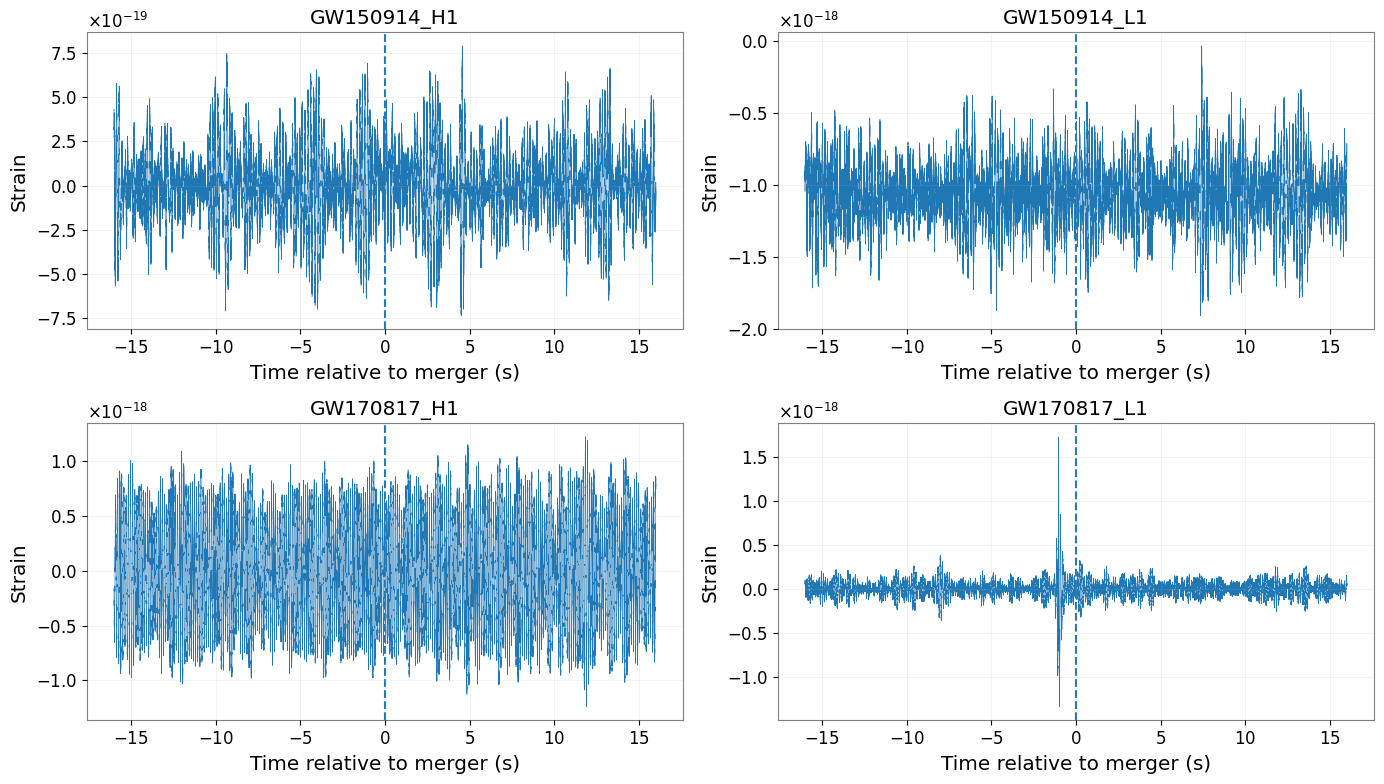

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (key, data) in zip(axes.flat, RAW_DATA.items()):

    t = data["timestamps"] - data["gps"]

    ax.plot(t, data["strain"], linewidth=0.4)
    ax.axvline(0, linestyle="--")
    ax.set_title(key)
    ax.set_xlabel("Time relative to merger (s)")
    ax.set_ylabel("Strain")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(PLOT_DIR / "raw_strain.png", dpi=150)
plt.show()

## Inspecting signal statistics

In [ ]:
stats = []

for key, data in RAW_DATA.items():

    x = data["strain"]

    stats.append({
        "dataset": key,
        "mean": np.mean(x),
        "std": np.std(x),
        "RMS": np.sqrt(np.mean(x**2)),
        "min": np.min(x),
        "max": np.max(x)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

assert len(stats_df) == 4
print("Signal statistics validated.")

,dataset,mean,std,RMS,min,max
0,GW150914_H1,-3.800603e-22,2.244149e-19,2.244152e-19,-7.368665e-19,7.912043e-19
1,GW150914_L1,-1.064078e-18,2.356183e-19,1.089852e-18,-1.909168e-18,-3.058307e-20
2,GW170817_H1,1.964779e-22,5.398155e-19,5.398156e-19,-1.242727e-18,1.224485e-18
3,GW170817_L1,5.492767e-23,1.167206e-19,1.167206e-19,-1.345437e-18,1.732907e-18


Signal statistics validated.


# Power Spectral Density (PSD)

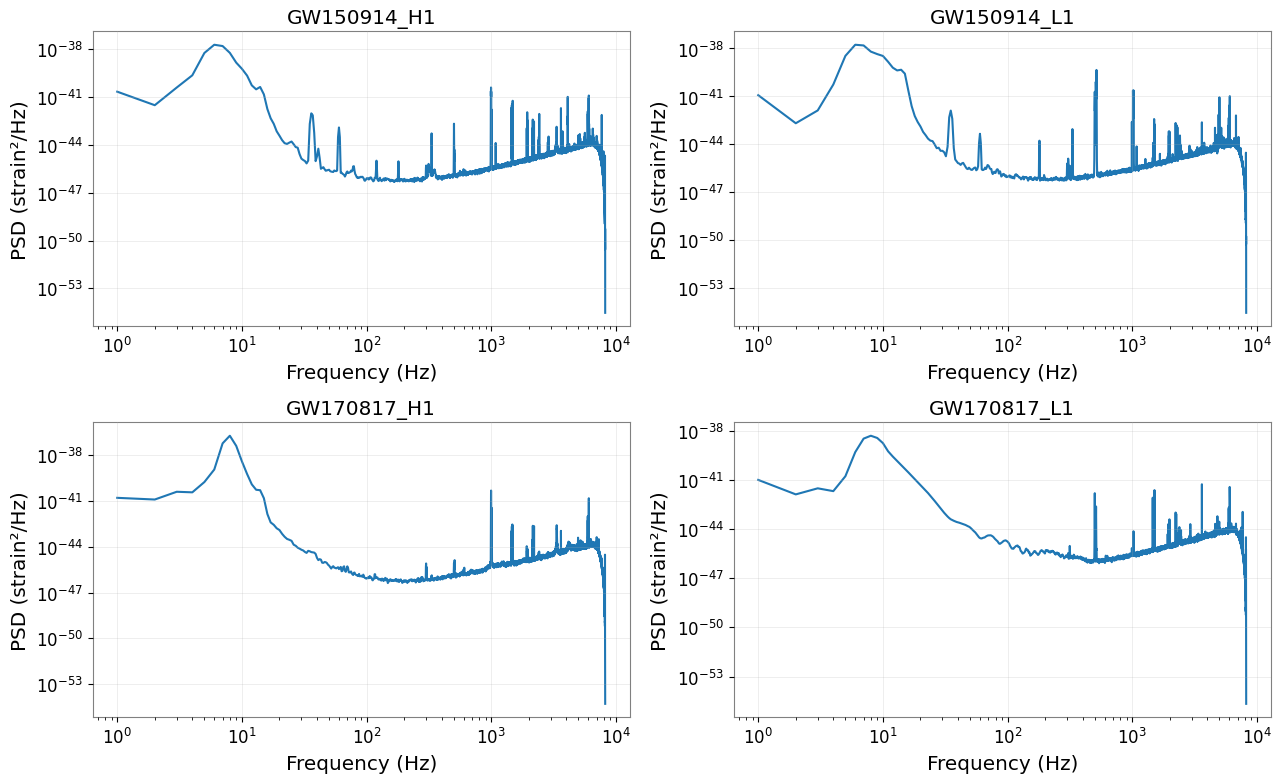

PSD analysis completed for 4 datasets.


In [ ]:
PSD_DATA = {}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, (key, data) in zip(axes.flat, RAW_DATA.items()):

    frequencies, psd = welch(
        data["strain"],
        fs=SAMPLE_RATE,
        nperseg=16384
    )

    PSD_DATA[key] = {
        "frequencies": frequencies,
        "psd": psd
    }

    ax.loglog(frequencies[1:], psd[1:])
    ax.set_title(key)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (strain²/Hz)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("PSD analysis completed for", len(PSD_DATA), "datasets.")

# Whitening

In [ ]:
WHITENED_DATA = {}

def whiten_signal(signal, fs):

    frequencies, psd = welch(
        signal,
        fs=fs,
        nperseg=16384
    )

    fft_values = np.fft.rfft(signal)
    fft_freq = np.fft.rfftfreq(len(signal), 1/fs)

    interpolated_psd = np.interp(
        fft_freq,
        frequencies,
        psd
    )

    white_fft = fft_values / np.sqrt(
        np.maximum(interpolated_psd, 1e-30)
    )

    whitened = np.fft.irfft(
        white_fft,
        n=len(signal)
    )

    whitened = (
        whitened - np.mean(whitened)
    ) / (np.std(whitened) + 1e-12)

    return whitened

for key, data in RAW_DATA.items():

    WHITENED_DATA[key] = whiten_signal(
        data["strain"],
        SAMPLE_RATE
    )

    assert np.isfinite(WHITENED_DATA[key]).all()

print("Whitening completed.")
print("Datasets:", len(WHITENED_DATA))

Whitening completed.
Datasets: 4


# Bandpass filtering

In [ ]:
FILTERED_DATA = {}

sos = butter(
    4,
    [20, 1000],
    btype="bandpass",
    fs=SAMPLE_RATE,
    output="sos"
)

for key, signal in WHITENED_DATA.items():

    filtered = sosfiltfilt(sos, signal)

    FILTERED_DATA[key] = filtered

    assert np.isfinite(filtered).all()

print("Bandpass filtering completed.")

Bandpass filtering completed.


# Spectrogram analysis

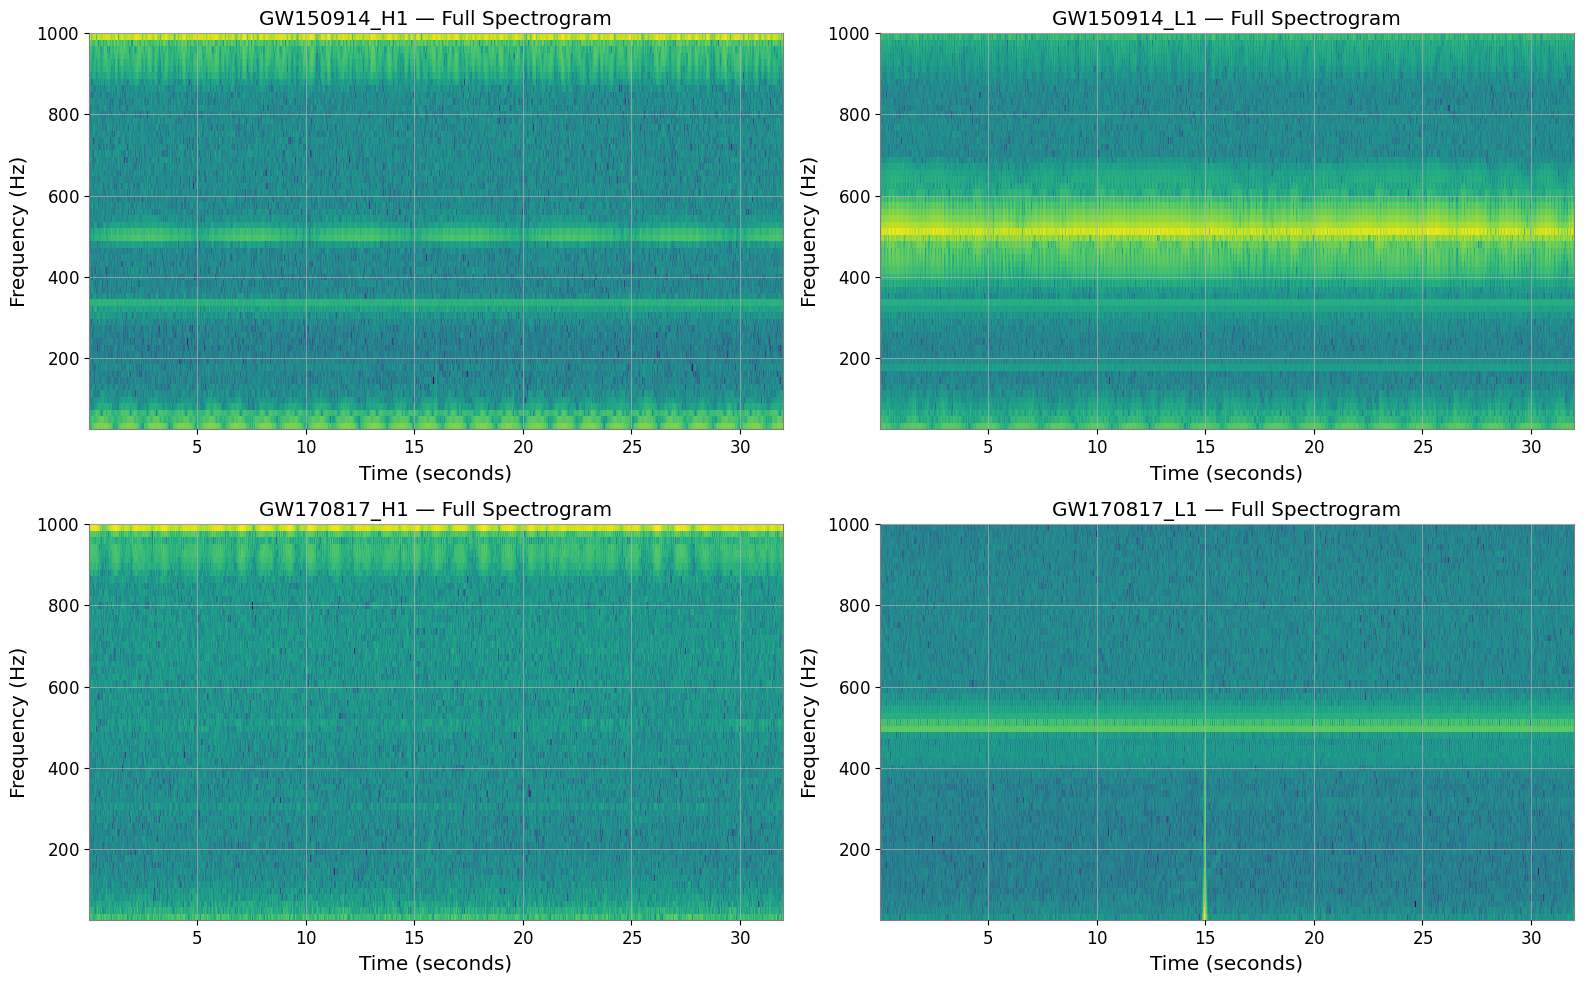

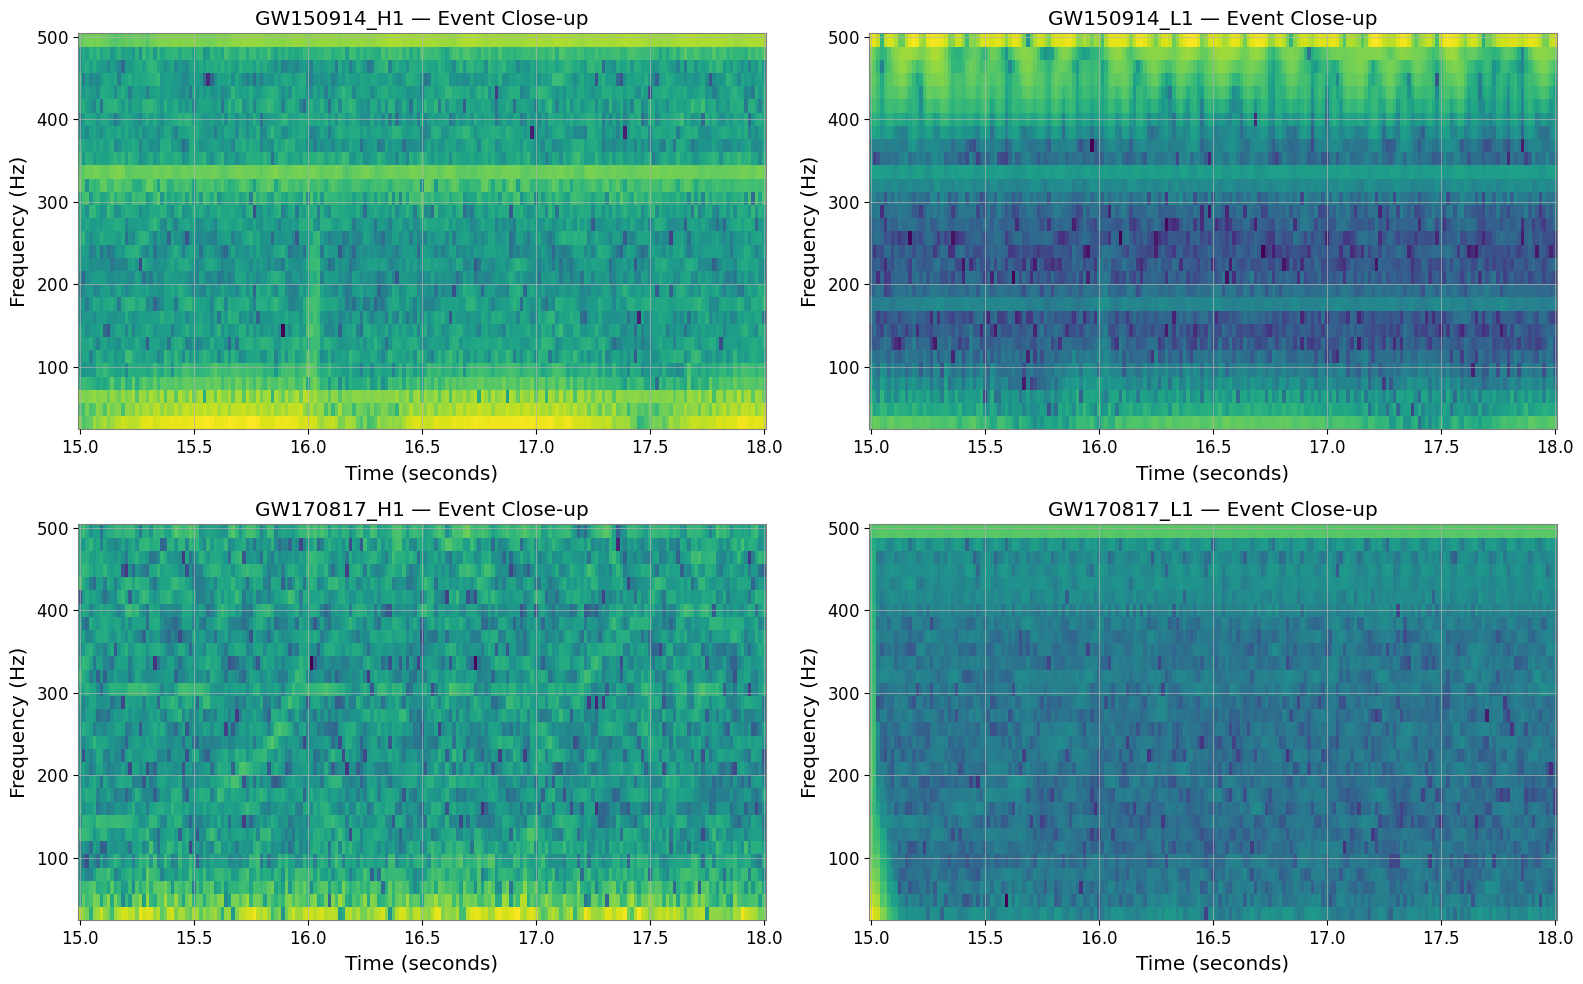

Full spectrograms: 4
Zoomed spectrograms generated successfully.


In [ ]:
# SPECTROGRAM ANALYSIS

SPECTROGRAM_DATA = {}

# Adjusting these to zoom into the event
ZOOM_START = 15
ZOOM_END = 18

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

for ax, (key, signal) in zip(
    axes.flat,
    FILTERED_DATA.items()
):

    frequencies, times, power = spectrogram(
        signal,
        fs=SAMPLE_RATE,
        nperseg=1024,
        noverlap=768
    )

    SPECTROGRAM_DATA[key] = {
        "frequencies": frequencies,
        "times": times,
        "power": power
    }

    # Frequency range
    freq_mask = (
        (frequencies >= 20) &
        (frequencies <= 1000)
    )

    # Full spectrogram
    ax.pcolormesh(
        times,
        frequencies[freq_mask],
        10 * np.log10(
            power[freq_mask] + 1e-20
        ),
        shading="auto"
    )

    ax.set_title(f"{key} — Full Spectrogram")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# Close up

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

for ax, (key, data) in zip(
    axes.flat,
    SPECTROGRAM_DATA.items()
):

    frequencies = data["frequencies"]
    times = data["times"]
    power = data["power"]

    # Time zoom
    time_mask = (
        (times >= ZOOM_START) &
        (times <= ZOOM_END)
    )

    # Frequency zoom
    freq_mask = (
        (frequencies >= 20) &
        (frequencies <= 500)
    )

    zoom_power = power[
        np.ix_(freq_mask, time_mask)
    ]

    ax.pcolormesh(
        times[time_mask],
        frequencies[freq_mask],
        10 * np.log10(
            zoom_power + 1e-20
        ),
        shading="auto"
    )

    ax.set_title(f"{key} — Event Close-up")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

print("Full spectrograms:", len(SPECTROGRAM_DATA))
print("Zoomed spectrograms generated successfully.")

# Compare H1 and L1

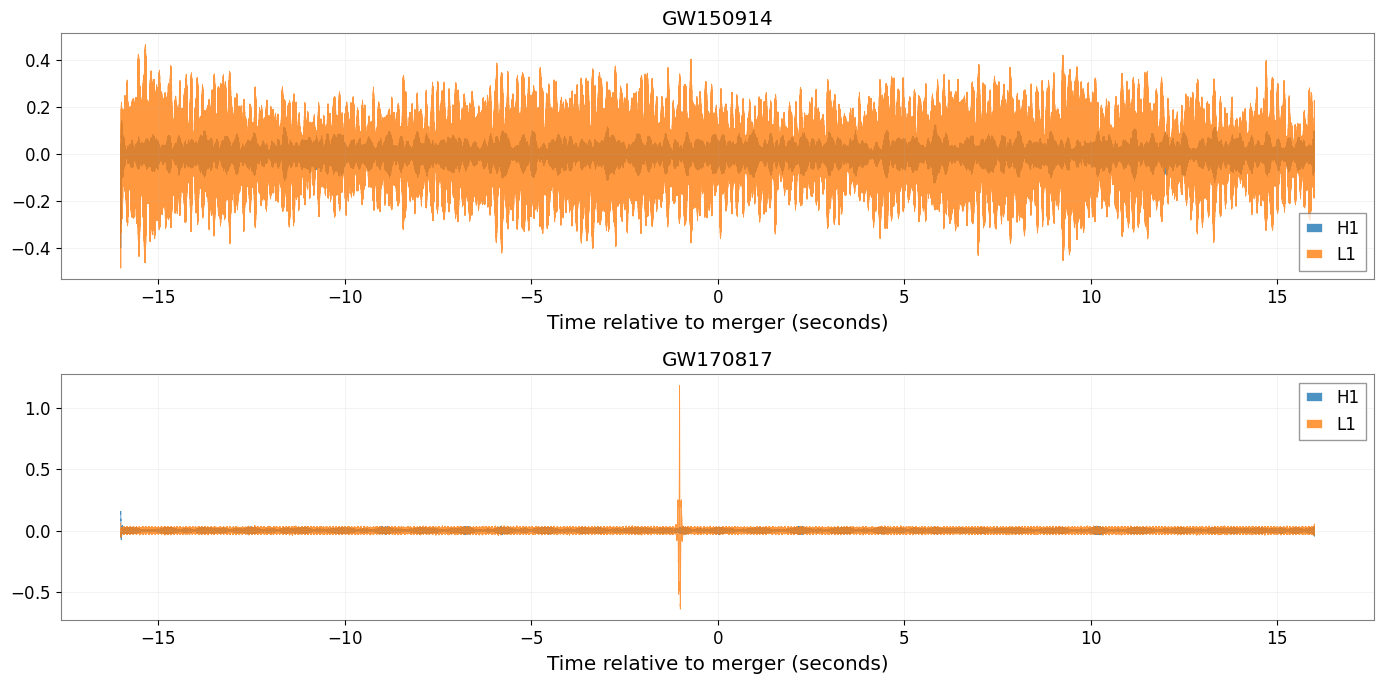

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for ax, event in zip(axes, EVENTS):

    h1 = FILTERED_DATA[f"{event}_H1"]
    l1 = FILTERED_DATA[f"{event}_L1"]

    t = RAW_DATA[f"{event}_H1"]["timestamps"]
    t = t - RAW_DATA[f"{event}_H1"]["gps"]

    ax.plot(t, h1, label="H1", alpha=0.8, linewidth=0.6)
    ax.plot(t, l1, label="L1", alpha=0.8, linewidth=0.6)

    ax.set_title(event)
    ax.set_xlabel("Time relative to merger (seconds)")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
assert len(PSD_DATA) == 4
assert len(WHITENED_DATA) == 4
assert len(FILTERED_DATA) == 4
assert len(SPECTROGRAM_DATA) == 4

print("NEURO//WAVE MODULE 02 COMPLETE")
print("PSD: PASS")
print("Whitening: PASS")
print("Filtering: PASS")
print("Spectrograms: PASS")
print("Detector comparison: GENERATED")

NEURO//WAVE MODULE 02 COMPLETE
PSD: PASS
Whitening: PASS
Filtering: PASS
Spectrograms: PASS
Detector comparison: GENERATED


## AI Dataset Construction

In [ ]:
!pip -q install pycbc


# Downloading independent background noise

In [ ]:
TRAIN_FS = 4096
WINDOW = 8
BACKGROUND_DATA = {}

for event, gps in EVENT_TIMES.items():
    for detector in DETECTORS:

        key = f"{event}_{detector}"

        try:
            background = TimeSeries.fetch_open_data(
                detector,
                gps - 1200,
                gps - 944,
                sample_rate=TRAIN_FS,
                cache=True
            )

            x = np.asarray(background.value, dtype=np.float32)

            assert np.isfinite(x).all()
            assert len(x) == 256 * TRAIN_FS

            BACKGROUND_DATA[key] = x

            print(key, "SUCCESS:", len(x), "samples")

        except Exception as e:
            print(key, "FAILED:", repr(e))

print("Background datasets:", len(BACKGROUND_DATA))

GW150914_H1 SUCCESS: 1048576 samples
GW150914_L1 SUCCESS: 1048576 samples
GW170817_H1 SUCCESS: 1048576 samples
GW170817_L1 SUCCESS: 1048576 samples
Background datasets: 4


# Generating astrophysical waveforms

In [ ]:
WAVEFORMS = {}

waveform_configs = {
    "BBH": {
        "approximant": "IMRPhenomD",
        "mass1": 30,
        "mass2": 25,
        "f_lower": 30
    },
    "BNS": {
        "approximant": "IMRPhenomD_NRTidalv2",
        "mass1": 1.4,
        "mass2": 1.4,
        "f_lower": 30
    }
}

for name, config in waveform_configs.items():

    hp, hc = get_td_waveform(
        **config,
        delta_t=1/TRAIN_FS
    )

    waveform = np.asarray(hp, dtype=np.float32)

    waveform = waveform[-WINDOW * TRAIN_FS:]

    WAVEFORMS[name] = waveform

    print(name, "waveform samples:", len(waveform))

print("Waveform generation completed.")

/usr/lib/python3.13/importlib/__init__.py:88: UserWarning: Wswiglal-redir-stdio:
----------------------------------------------------------------
SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
----------------------------------------------------------------

  return _bootstrap._gcd_import(name[level:], package, level)


BBH waveform samples: 32768
BNS waveform samples: 32768
Waveform generation completed.


## Constructing labelled dataset

In [ ]:
X = []
y = []
groups = []

rng = np.random.default_rng(42)

for source, background in BACKGROUND_DATA.items():

    chunks = background.reshape(
        -1, WINDOW * TRAIN_FS
    )

    for i, noise in enumerate(chunks):

        # Background-only example
        X.append(noise.copy())
        y.append(0)
        groups.append(f"{source}_{i}")

        # BBH and BNS injections
        for class_name, waveform in WAVEFORMS.items():

            signal = np.zeros_like(noise)

            n = min(len(waveform), len(signal))

            signal[-n:] = waveform[-n:]

            target_ratio = rng.uniform(0.5, 3.0)

            signal *= (
                target_ratio * np.std(noise) /
                (np.max(np.abs(signal)) + 1e-12)
            )

            injected = noise + signal

            X.append(injected.astype(np.float32))
            y.append(1)
            groups.append(f"{source}_{i}")

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)
groups = np.asarray(groups)

print("Dataset shape:", X.shape)
print("Labels:", np.unique(y, return_counts=True))

assert X.ndim == 2
assert len(X) == len(y)
assert np.isfinite(X).all()

Dataset shape: (384, 32768)
Labels: (array([0, 1], dtype=int32), array([128, 256]))


## Preventing data leakage

In [ ]:
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups)
)

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_rel, test_rel = next(
    split2.split(
        X[temp_idx],
        y[temp_idx],
        groups[temp_idx]
    )
)

val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

assert not (
    set(groups[train_idx]) & set(groups[test_idx])
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Group leakage: NONE")

Training: (267, 32768)
Validation: (57, 32768)
Testing: (60, 32768)
Group leakage: NONE


In [ ]:
np.savez_compressed(
    DATA_DIR / "neuro_wave_training.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

print("Training dataset saved successfully.")

Training dataset saved successfully.


# AI Detection Engine

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Preparing model inputs

In [ ]:
# Adding channel dimension for Conv1D

X_train_model = X_train[..., np.newaxis]
X_val_model = X_val[..., np.newaxis]
X_test_model = X_test[..., np.newaxis]

print("Training:", X_train_model.shape)
print("Validation:", X_val_model.shape)
print("Testing:", X_test_model.shape)

assert X_train_model.shape[1:] == (32768, 1)

Training: (267, 32768, 1)
Validation: (57, 32768, 1)
Testing: (60, 32768, 1)


## Building the CNN

In [ ]:
tf.keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(32768, 1)),

    layers.Conv1D(16, 64, strides=4, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling1D(4),

    layers.Conv1D(32, 32, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling1D(4),

    layers.Conv1D(64, 16, padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8192, 16)       │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8192, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 8192, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2048, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2048, 32)       │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2048, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 2048, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 512, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 512, 64)        │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 512, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,961 (214.69 KB)

 Trainable params: 54,737 (213.82 KB)

 Non-trainable params: 224 (896.00 B)

## Training the detection model

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        str(BASE_DIR / "best_detector.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train_model,
    y_train,
    validation_data=(X_val_model, y_val),
    epochs=25,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 379ms/step - accuracy: 0.6517 - auc: 0.5483 - loss: 0.6568 - precision: 0.6693 - recall: 0.9438 - val_accuracy: 0.6667 - val_auc: 0.5000 - val_loss: 0.6739 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 2/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 412ms/step - accuracy: 0.6667 - auc: 0.4490 - loss: 0.6499 - precision: 0.6667 - recall: 1.0000 - val_accuracy: 0.6667 - val_auc: 0.5000 - val_loss: 0.6703 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 3/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 293ms/step - accuracy: 0.6667 - auc: 0.5030 - loss: 0.6391 - precision: 0.6667 - recall: 1.0000 - val_accuracy: 0.6667 - val_auc: 0.5000 - val_loss: 0.6681 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 4/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 286ms/step - accuracy: 0.6667 - auc: 0.5351 - loss: 0.6340 - precision: 0.6667 - recall: 1.0000 - val_accuracy: 0.6667 - val_auc: 0.5000 - val_loss: 0.6675 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 5/25
17/17 ━━━━━━━━━━━━━

# Training visualisation

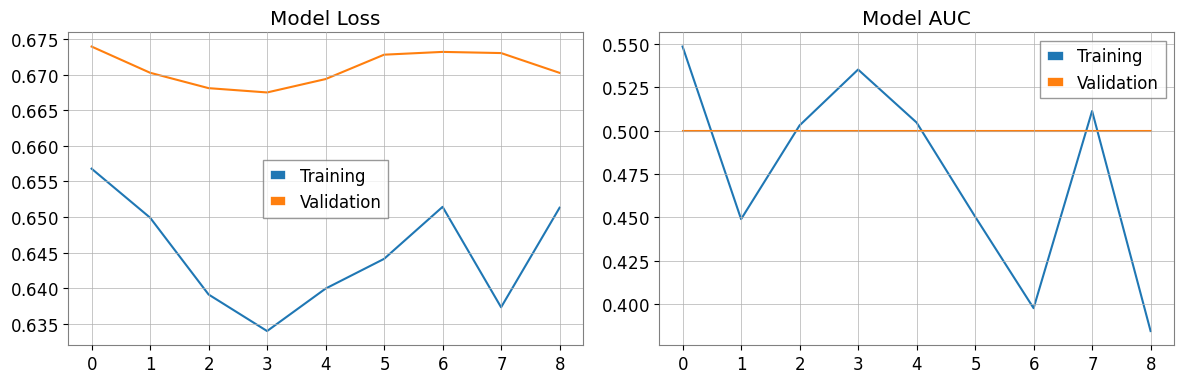

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Model Loss")
axes[0].legend()

axes[1].plot(history.history["auc"], label="Training")
axes[1].plot(history.history["val_auc"], label="Validation")
axes[1].set_title("Model AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
model.save(BASE_DIR / "NEURO_WAVE_CNN.keras")

print("CNN model saved successfully.")

CNN model saved successfully.


# Rebuilding the background dataset

# Expanded background acquisition

In [ ]:
TRAIN_FS = 4096
BACKGROUND_DURATION = 256
NUM_INTERVALS = 10

BACKGROUND_PAIRS = {}
BACKGROUND_REPORT = []

for event, gps in EVENT_TIMES.items():

    for i in range(NUM_INTERVALS):

        # Separating intervals with a 64-second gap
        start = gps - (1200 + i * 320)
        end = start + BACKGROUND_DURATION

        pair_key = f"{event}_BG_{i:02d}"

        try:

            h1 = TimeSeries.fetch_open_data(
                "H1", start, end,
                sample_rate=TRAIN_FS,
                cache=True
            )

            l1 = TimeSeries.fetch_open_data(
                "L1", start, end,
                sample_rate=TRAIN_FS,
                cache=True
            )

            h1_values = np.asarray(
                h1.value, dtype=np.float32
            )

            l1_values = np.asarray(
                l1.value, dtype=np.float32
            )

            expected = TRAIN_FS * BACKGROUND_DURATION

            assert len(h1_values) == expected
            assert len(l1_values) == expected

            assert np.isfinite(h1_values).all()
            assert np.isfinite(l1_values).all()

            # Two synchronized detector channels
            paired = np.stack(
                [h1_values, l1_values],
                axis=-1
            )

            BACKGROUND_PAIRS[pair_key] = paired

            BACKGROUND_REPORT.append({
                "interval": pair_key,
                "samples": len(paired),
                "channels": 2,
                "status": "SUCCESS"
            })

            print(pair_key, "SUCCESS")

        except Exception as error:

            BACKGROUND_REPORT.append({
                "interval": pair_key,
                "samples": 0,
                "channels": 0,
                "status": repr(error)
            })

            print(pair_key, "FAILED:", repr(error))


background_df = pd.DataFrame(BACKGROUND_REPORT)

display(background_df)

print("\nSuccessful paired intervals:", len(BACKGROUND_PAIRS))
print("Expected:", 20)


GW150914_BG_00 SUCCESS
GW150914_BG_01 SUCCESS
GW150914_BG_02 SUCCESS
GW150914_BG_03 SUCCESS
GW150914_BG_04 SUCCESS
GW150914_BG_05 FAILED: AssertionError()
GW150914_BG_06 FAILED: GetExceptionGroup('failed to get data from any source', [ValueError('No data found for L1 in [1126256342.4 .. 1126256598.4), last error: Cannot find a GWOSC dataset for L1 covering [1126256342, 1126256599)')])
GW150914_BG_07 FAILED: GetExceptionGroup('failed to get data from any source', [ValueError('No data found for L1 in [1126256022.4 .. 1126256278.4), last error: Cannot find a GWOSC dataset for L1 covering [1126256022, 1126256279)')])
GW150914_BG_08 FAILED: GetExceptionGroup('failed to get data from any source', [ValueError('No data found for L1 in [1126255702.4 .. 1126255958.4), last error: Cannot find a GWOSC dataset for L1 covering [1126255702, 1126255959)')])
GW150914_BG_09 FAILED: GetExceptionGroup('failed to get data from any source', [ValueError('No data found for L1 in [1126255382.4 .. 1126255638.4)

,interval,samples,channels,status
0,GW150914_BG_00,1048576,2,SUCCESS
1,GW150914_BG_01,1048576,2,SUCCESS
2,GW150914_BG_02,1048576,2,SUCCESS
3,GW150914_BG_03,1048576,2,SUCCESS
4,GW150914_BG_04,1048576,2,SUCCESS
5,GW150914_BG_05,0,0,AssertionError()
6,GW150914_BG_06,0,0,GetExceptionGroup('failed to get data from any...
7,GW150914_BG_07,0,0,GetExceptionGroup('failed to get data from any...
8,GW150914_BG_08,0,0,GetExceptionGroup('failed to get data from any...
9,GW150914_BG_09,0,0,GetExceptionGroup('failed to get data from any...



Successful paired intervals: 15
Expected: 20


In [ ]:
BACKGROUND_DIR = DATA_DIR / "background"
BACKGROUND_DIR.mkdir(parents=True, exist_ok=True)

for key, values in BACKGROUND_PAIRS.items():

    np.savez_compressed(
        BACKGROUND_DIR / f"{key}.npz",
        strain=values,
        sample_rate=TRAIN_FS,
        detectors=["H1", "L1"]
    )

assert all(
    x.shape == (256 * 4096, 2)
    for x in BACKGROUND_PAIRS.values()
)

print("Background validation passed.")
print("Total intervals:", len(BACKGROUND_PAIRS))
print(
    "Total paired samples:",
    sum(len(x) for x in BACKGROUND_PAIRS.values())
)


Background validation passed.
Total intervals: 15
Total paired samples: 15728640


# Preparing paired background windows

In [ ]:
TRAIN_FS = 4096
WINDOW_SECONDS = 8
WINDOW_SAMPLES = TRAIN_FS * WINDOW_SECONDS

BACKGROUND_WINDOWS = []
WINDOW_GROUPS = []
WINDOW_METADATA = []

for interval_name, paired in BACKGROUND_PAIRS.items():

    paired = np.asarray(paired, dtype=np.float32)

    # Require synchronized H1 and L1 channels
    assert paired.ndim == 2 and paired.shape[1] == 2
    assert paired.shape[0] % WINDOW_SAMPLES == 0
    assert np.isfinite(paired).all()

    number_of_windows = paired.shape[0] // WINDOW_SAMPLES

    for i in range(number_of_windows):
        start = i * WINDOW_SAMPLES
        end = start + WINDOW_SAMPLES

        window = paired[start:end]

        BACKGROUND_WINDOWS.append(window)
        WINDOW_GROUPS.append(interval_name)

        WINDOW_METADATA.append({
            "interval": interval_name,
            "window": i,
            "samples": len(window)
        })

BACKGROUND_WINDOWS = np.stack(BACKGROUND_WINDOWS)
WINDOW_GROUPS = np.asarray(WINDOW_GROUPS)

window_df = pd.DataFrame(WINDOW_METADATA)

print("Background windows:", BACKGROUND_WINDOWS.shape)
print("Unique intervals:", len(np.unique(WINDOW_GROUPS)))
print("Window duration:", WINDOW_SECONDS, "seconds")
print("Channels: H1, L1")

display(window_df.groupby("interval").size().to_frame("windows"))


Background windows: (480, 32768, 2)
Unique intervals: 15
Window duration: 8 seconds
Channels: H1, L1


,windows
interval,
GW150914_BG_00,32
GW150914_BG_01,32
GW150914_BG_02,32
GW150914_BG_03,32
GW150914_BG_04,32
GW170817_BG_00,32
GW170817_BG_01,32
GW170817_BG_02,32
GW170817_BG_03,32


# PSD-based whitening Again

In [ ]:
from collections import Counter

print("BACKGROUND_WINDOWS:", len(BACKGROUND_WINDOWS))
print("WINDOW_GROUPS:", len(WINDOW_GROUPS))
print("BACKGROUND_PAIRS:", len(BACKGROUND_PAIRS))

print("\nWindows per group:")

group_counts = Counter(WINDOW_GROUPS)

for group, count in group_counts.items():
    print(f"{group}: {count}")

print("\nGroups missing PSD estimates:")

for group in group_counts:
    if group not in BACKGROUND_PAIRS:
        print(group, "->", group_counts[group], "windows")

print("\nGroups without windows:")

for group in BACKGROUND_PAIRS:
    if group not in group_counts:
        print(group)

BACKGROUND_WINDOWS: 480
WINDOW_GROUPS: 480
BACKGROUND_PAIRS: 15

Windows per group:
GW150914_BG_00: 32
GW150914_BG_01: 32
GW150914_BG_02: 32
GW150914_BG_03: 32
GW150914_BG_04: 32
GW170817_BG_00: 32
GW170817_BG_01: 32
GW170817_BG_02: 32
GW170817_BG_03: 32
GW170817_BG_04: 32
GW170817_BG_05: 32
GW170817_BG_06: 32
GW170817_BG_07: 32
GW170817_BG_08: 32
GW170817_BG_09: 32

Groups missing PSD estimates:

Groups without windows:


In [ ]:
print("BACKGROUND_WINDOWS:", len(BACKGROUND_WINDOWS))

print("WHITENED_WINDOWS exists:",
      "WHITENED_WINDOWS" in globals())

print("Related variables:",
      [v for v in globals()
       if "WHITEN" in v.upper()])

BACKGROUND_WINDOWS: 480
WHITENED_WINDOWS exists: False
Related variables: ['WHITENED_DATA', 'whiten_signal']


In [ ]:
WHITENED_WINDOWS = []

In [ ]:
print("Expected windows:", 480)
print("Actual windows:", len(BACKGROUND_WINDOWS))

print(
    "Unprocessed windows:",
    len(BACKGROUND_WINDOWS) - len(WHITENED_WINDOWS)
)

Expected windows: 480
Actual windows: 480
Unprocessed windows: 480


In [ ]:
print("BACKGROUND_PAIRS KEYS:")

for key in BACKGROUND_PAIRS:
    print(key)

print("\nALL EXPECTED GROUPS:")

EXPECTED_GROUPS = [
    f"GW150914_BG_{i:02d}"
    for i in range(5)
] + [
    f"GW170817_BG_{i:02d}"
    for i in range(10)
]

for group in EXPECTED_GROUPS:
    status = (
        "AVAILABLE"
        if group in BACKGROUND_PAIRS
        else "MISSING"
    )

    print(group, status)

BACKGROUND_PAIRS KEYS:
GW150914_BG_00
GW150914_BG_01
GW150914_BG_02
GW150914_BG_03
GW150914_BG_04
GW170817_BG_00
GW170817_BG_01
GW170817_BG_02
GW170817_BG_03
GW170817_BG_04
GW170817_BG_05
GW170817_BG_06
GW170817_BG_07
GW170817_BG_08
GW170817_BG_09

ALL EXPECTED GROUPS:
GW150914_BG_00 AVAILABLE
GW150914_BG_01 AVAILABLE
GW150914_BG_02 AVAILABLE
GW150914_BG_03 AVAILABLE
GW150914_BG_04 AVAILABLE
GW170817_BG_00 AVAILABLE
GW170817_BG_01 AVAILABLE
GW170817_BG_02 AVAILABLE
GW170817_BG_03 AVAILABLE
GW170817_BG_04 AVAILABLE
GW170817_BG_05 AVAILABLE
GW170817_BG_06 AVAILABLE
GW170817_BG_07 AVAILABLE
GW170817_BG_08 AVAILABLE
GW170817_BG_09 AVAILABLE


In [ ]:
print("Available acquisition-related variables:\n")

for name, obj in list(globals().copy().items()):

    if any(
        term in name.lower()
        for term in [
            "background",
            "interval",
            "failed",
            "success",
            "gw170817"
        ]
    ):
        try:
            print(name, type(obj), len(obj))
        except (TypeError, AttributeError):
            print(name, type(obj))

Available acquisition-related variables:

BACKGROUND_DATA <class 'dict'> 4
background <class 'numpy.ndarray'> 1048576
BACKGROUND_DURATION <class 'int'>
NUM_INTERVALS <class 'int'>
BACKGROUND_PAIRS <class 'dict'> 15
BACKGROUND_REPORT <class 'list'> 20
background_df <class 'pandas.core.frame.DataFrame'> 20
BACKGROUND_DIR <class 'pathlib._local.PosixPath'>
BACKGROUND_WINDOWS <class 'numpy.ndarray'> 480
interval_name <class 'str'> 14
interval_names <class 'numpy.ndarray'> 15
train_intervals <class 'numpy.ndarray'> 12
val_intervals <class 'numpy.ndarray'> 3


In [ ]:
TRAIN_FS = 4096
TARGET_FS = 1024

WINDOW_SECONDS = 8
WINDOW_SAMPLES = TRAIN_FS * WINDOW_SECONDS

PSD_DATA = {}
WHITENED_WINDOWS = []

for interval_name, paired in BACKGROUND_PAIRS.items():

    print("Estimating PSD:", interval_name)

    psd_channels = []

    for channel in range(2):

        frequencies, psd = welch(
            paired[:, channel],
            fs=TRAIN_FS,
            nperseg=8 * TRAIN_FS,
            noverlap=4 * TRAIN_FS,
            average="median"
        )

        psd = np.maximum(
            psd,
            np.max(psd) * 1e-12
        )

        psd_channels.append((frequencies, psd))

    PSD_DATA[interval_name] = psd_channels


def whiten_signal(signal, frequencies, psd):

    signal = np.asarray(signal, dtype=np.float64)

    fft_data = np.fft.rfft(signal)

    fft_freq = np.fft.rfftfreq(
        len(signal),
        d=1 / TRAIN_FS
    )

    interpolated_psd = np.interp(
        fft_freq,
        frequencies,
        psd
    )

    interpolated_psd = np.maximum(
        interpolated_psd,
        np.max(interpolated_psd) * 1e-12
    )

    # Frequency-domain whitening
    whitened_fft = fft_data / np.sqrt(interpolated_psd)

    # Retain gravitational-wave frequency band
    valid_band = (
        (fft_freq >= 20) &
        (fft_freq <= 500)
    )

    whitened_fft[~valid_band] = 0

    whitened = np.fft.irfft(
        whitened_fft,
        n=len(signal)
    )

    return whitened.astype(np.float32)


for interval_name in BACKGROUND_PAIRS:

    indices = np.where(
        WINDOW_GROUPS == interval_name
    )[0]

    frequencies_pair = PSD_DATA[interval_name]

    for idx in indices:

        paired = BACKGROUND_WINDOWS[idx]

        channels = []

        for channel in range(2):

            frequencies, psd = frequencies_pair[channel]

            whitened = whiten_signal(
                paired[:, channel],
                frequencies,
                psd
            )

            channels.append(whitened)

        whitened_pair = np.stack(
            channels,
            axis=-1
        )

        # Downsample from 4096 Hz to 1024 Hz
        whitened_pair = resample_poly(
            whitened_pair,
            up=1,
            down=4,
            axis=0
        )

        WHITENED_WINDOWS.append(
            whitened_pair.astype(np.float32)
        )


WHITENED_WINDOWS = np.stack(
    WHITENED_WINDOWS
)

print("Whitened dataset:", WHITENED_WINDOWS.shape)
print("Sampling frequency:", TARGET_FS)
print("Window duration:", WINDOW_SECONDS)
print("Detector channels: H1, L1")

assert WHITENED_WINDOWS.shape == (480, 8192, 2)

assert np.isfinite(WHITENED_WINDOWS).all()

print("Whitening validation passed.")

Estimating PSD: GW150914_BG_00
Estimating PSD: GW150914_BG_01
Estimating PSD: GW150914_BG_02
Estimating PSD: GW150914_BG_03
Estimating PSD: GW150914_BG_04
Estimating PSD: GW170817_BG_00
Estimating PSD: GW170817_BG_01
Estimating PSD: GW170817_BG_02
Estimating PSD: GW170817_BG_03
Estimating PSD: GW170817_BG_04
Estimating PSD: GW170817_BG_05
Estimating PSD: GW170817_BG_06
Estimating PSD: GW170817_BG_07
Estimating PSD: GW170817_BG_08
Estimating PSD: GW170817_BG_09
Whitened dataset: (480, 8192, 2)
Sampling frequency: 1024
Window duration: 8
Detector channels: H1, L1
Whitening validation passed.


# Generating simulated gravitational-wave templates

In [ ]:
WAVEFORM_BANK = {}

MASS_PAIRS = [
    (20, 15),
    (25, 20),
    (30, 20),
    (36, 29),
    (40, 30),
    (45, 35),
    (50, 40),
    (55, 45)
]

for mass1, mass2 in MASS_PAIRS:

    hp, hc = get_td_waveform(
        approximant="IMRPhenomD",
        mass1=mass1,
        mass2=mass2,
        distance=400,
        inclination=0.5,
        delta_t=1 / TRAIN_FS,
        f_lower=20
    )

    hp_values = np.asarray(
        hp,
        dtype=np.float32
    )

    hc_values = np.asarray(
        hc,
        dtype=np.float32
    )

    # Restrict maximum waveform duration to 8 seconds
    hp_values = hp_values[-WINDOW_SAMPLES:]
    hc_values = hc_values[-WINDOW_SAMPLES:]

    WAVEFORM_BANK[(mass1, mass2)] = {
        "plus": hp_values,
        "cross": hc_values
    }

    print(
        f"{mass1}/{mass2}:",
        len(hp_values),
        "samples"
    )

print("\nWaveform bank:", len(WAVEFORM_BANK))

20/15: 32768 samples
25/20: 32768 samples
30/20: 32768 samples
36/29: 32768 samples
40/30: 32768 samples
45/35: 32768 samples
50/40: 32768 samples
55/45: 32768 samples

Waveform bank: 8


# Inject signals into real H1/L1 backgrounds

In [ ]:
RNG = np.random.default_rng(42)

def shift_signal(signal, shift):

    output = np.zeros_like(signal)

    if shift > 0:
        output[shift:] = signal[:-shift]

    elif shift < 0:
        output[:shift] = signal[-shift:]

    else:
        output[:] = signal

    return output


def preprocess_pair(pair, interval_name):

    output = []

    for channel in range(2):

        frequencies, psd = PSD_DATA[
            interval_name
        ][channel]

        whitened = whiten_signal(
            pair[:, channel],
            frequencies,
            psd
        )

        output.append(whitened)

    output = np.stack(output, axis=-1)

    output = resample_poly(
        output,
        up=1,
        down=4,
        axis=0
    )

    return output.astype(np.float32)


def create_example(window_indices, inject=False):

    idx = RNG.choice(window_indices)

    raw_noise = BACKGROUND_WINDOWS[idx]

    interval_name = WINDOW_GROUPS[idx]

    # Process actual detector noise
    noise = preprocess_pair(
        raw_noise,
        interval_name
    )

    # Normalize using noise statistics only
    noise_std = np.std(
        noise,
        axis=0,
        keepdims=True
    )

    noise_std = np.maximum(
        noise_std,
        1e-12
    )

    noise = noise / noise_std

    if not inject:

        return noise.astype(np.float32), 0

    # Selecting physical waveform
    masses = list(WAVEFORM_BANK.keys())

    mass_pair = RNG.choice(len(masses))

    waveform = WAVEFORM_BANK[
        masses[mass_pair]
    ]

    hp = waveform["plus"]
    hc = waveform["cross"]

    # Random signal polarisation
    phase = RNG.uniform(0, 2 * np.pi)

    l1_wave = (
        hp * np.cos(phase) +
        hc * np.sin(phase)
    )

    # Approximate relative detector response
    l1_wave *= RNG.uniform(0.7, 1.3)

    # Random inter-detector time delay: +/- 10 ms
    delay = RNG.integers(
        -int(0.01 * TRAIN_FS),
        int(0.01 * TRAIN_FS) + 1
    )

    l1_wave = shift_signal(
        l1_wave,
        delay
    )

    # Random injection position
    length = len(hp)

    start = RNG.integers(
        0,
        WINDOW_SAMPLES - length + 1
    )

    injection = np.zeros_like(raw_noise)

    injection[start:start + length, 0] = hp

    injection[start:start + length, 1] = l1_wave

    # Whiten the injected signal with the same PSD
    injection_white = preprocess_pair(
        injection,
        interval_name
    )

    injection_white /= noise_std

    # Initial curriculum: network SNR 15-20
    target_snr = RNG.uniform(15, 20)

    signal_norm = np.linalg.norm(
        injection_white
    )

    if signal_norm < 1e-12:

        return noise.astype(np.float32), 0

    # Controlled network-SNR proxy
    injection_white *= (
        target_snr / signal_norm
    )

    combined = noise + injection_white

    return combined.astype(np.float32), 1

# Building training and validation datasets again

In [ ]:
interval_names = np.unique(
    WINDOW_GROUPS
)

train_intervals, val_intervals = train_test_split(
    interval_names,
    test_size=0.2,
    random_state=42
)

train_indices = np.where(
    np.isin(WINDOW_GROUPS, train_intervals)
)[0]

val_indices = np.where(
    np.isin(WINDOW_GROUPS, val_intervals)
)[0]

print("Training intervals:", len(train_intervals))
print("Validation intervals:", len(val_intervals))


def build_dataset(number_of_samples, indices):

    X = []
    y = []

    for i in range(number_of_samples):

        inject = (i % 2 == 0)

        sample, label = create_example(
            indices,
            inject=inject
        )

        X.append(sample)
        y.append(label)

        if (i + 1) % 200 == 0:

            print(
                f"Generated {i + 1}/{number_of_samples}"
            )

    return (
        np.stack(X).astype(np.float32),
        np.asarray(y, dtype=np.int32)
    )


X_train, y_train = build_dataset(
    2400,
    train_indices
)

X_val, y_val = build_dataset(
    600,
    val_indices
)

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)

print("Training positive:", np.sum(y_train == 1))
print("Training negative:", np.sum(y_train == 0))

print("Validation positive:", np.sum(y_val == 1))
print("Validation negative:", np.sum(y_val == 0))

assert X_train.shape[1:] == (8192, 2)
assert X_val.shape[1:] == (8192, 2)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

print("Dataset validation passed.")

Training intervals: 12
Validation intervals: 3
Generated 200/2400
Generated 400/2400
Generated 600/2400
Generated 800/2400
Generated 1000/2400
Generated 1200/2400
Generated 1400/2400
Generated 1600/2400
Generated 1800/2400
Generated 2000/2400
Generated 2200/2400
Generated 2400/2400
Generated 200/600
Generated 400/600
Generated 600/600

Training: (2400, 8192, 2)
Validation: (600, 8192, 2)
Training positive: 1200
Training negative: 1200
Validation positive: 300
Validation negative: 300
Dataset validation passed.


In [ ]:
ML_DIR = DATA_DIR / "ml_dataset"

ML_DIR.mkdir(
    parents=True,
    exist_ok=True
)

np.savez_compressed(
    ML_DIR / "GW150914_training.npz",
    X=X_train,
    y=y_train
)

np.savez_compressed(
    ML_DIR / "GW150914_validation.npz",
    X=X_val,
    y=y_val
)

print("Training datasets saved.")

Training datasets saved.


# Matched-filter-inspired CNN

In [ ]:
print("Waveform bank size:", len(WAVEFORM_BANK))

for mass_pair, waveform in WAVEFORM_BANK.items():

    hp = waveform["plus"]

    print(
        mass_pair,
        "Length:", len(hp),
        "Max:", np.max(np.abs(hp)),
        "Finite:", np.isfinite(hp).all()
    )

Waveform bank size: 8
(20, 15) Length: 32768 Max: 8.935065e-22 Finite: True
(25, 20) Length: 32768 Max: 1.1382011e-21 Finite: True
(30, 20) Length: 32768 Max: 1.2601292e-21 Finite: True
(36, 29) Length: 32768 Max: 1.6681694e-21 Finite: True
(40, 30) Length: 32768 Max: 1.8038085e-21 Finite: True
(45, 35) Length: 32768 Max: 2.0437714e-21 Finite: True
(50, 40) Length: 32768 Max: 2.339663e-21 Finite: True
(55, 45) Length: 32768 Max: 2.5631766e-21 Finite: True


In [ ]:
KERNEL_SIZE = 1024

sos = butter(
    4,
    [20, 500],
    btype="bandpass",
    fs=TARGET_FS,
    output="sos"
)

template_kernels = []
template_names = []

for mass_pair, waveform in WAVEFORM_BANK.items():

    hp = np.asarray(
        waveform["plus"],
        dtype=np.float64
    )

    # Checking waveform
    if len(hp) == 0 or not np.isfinite(hp).all():
        continue

    # Removing tiny physical strain scale
    scale = np.max(np.abs(hp))

    if scale < 1e-100:
        continue

    hp = hp / scale

    # Resample 4096 Hz -> 1024 Hz
    template = resample_poly(
        hp,
        up=1,
        down=4
    )

    # Bandpass
    template = sosfiltfilt(
        sos,
        template
    )

    # Keeping final 1024 samples
    template = template[-KERNEL_SIZE:]

    if len(template) < KERNEL_SIZE:

        template = np.pad(
            template,
            (KERNEL_SIZE - len(template), 0)
        )

    # Removing DC component
    template -= np.mean(template)

    # L2 normalization
    norm = np.linalg.norm(template)

    if not np.isfinite(norm) or norm < 1e-12:
        print("SKIPPED:", mass_pair, norm)
        continue

    template /= norm

    # Two detector channels
    kernel = np.zeros(
        (KERNEL_SIZE, 2),
        dtype=np.float32
    )

    kernel[:, 0] = template / np.sqrt(2)
    kernel[:, 1] = template / np.sqrt(2)

    template_kernels.extend([
        kernel,
        -kernel
    ])

    template_names.extend([
        f"{mass_pair}_positive",
        f"{mass_pair}_negative"
    ])

    print("ACCEPTED:", mass_pair)


template_kernels = np.stack(
    template_kernels,
    axis=-1
)

print("\nTemplate bank created.")
print("Shape:", template_kernels.shape)
print("Filters:", template_kernels.shape[-1])

assert template_kernels.shape == (1024, 2, 16)
assert np.isfinite(template_kernels).all()

ACCEPTED: (20, 15)
ACCEPTED: (25, 20)
ACCEPTED: (30, 20)
ACCEPTED: (36, 29)
ACCEPTED: (40, 30)
ACCEPTED: (45, 35)
ACCEPTED: (50, 40)
ACCEPTED: (55, 45)

Template bank created.
Shape: (1024, 2, 16)
Filters: 16


# Building the physics-informed CNN-BiGRU

# Model architecture

In [ ]:
tf.keras.backend.clear_session()

INPUT_SHAPE = (8192, 2)

inputs = layers.Input(
    shape=INPUT_SHAPE,
    name="detector_input"
)
# Physics-informed CNN
template_layer = layers.Conv1D(
    filters=16,
    kernel_size=1024,
    strides=8,
    padding="same",
    activation="relu",
    use_bias=False,
    trainable=True,
    name="physics_template_cnn"
)

x = template_layer(inputs)

template_layer.set_weights([
    template_kernels
])

print("Template initialisation:", template_layer.get_weights()[0].shape)

# Local feature extraction

x = layers.MaxPooling1D(
    pool_size=4
)(x)

x = layers.Conv1D(
    filters=32,
    kernel_size=9,
    padding="same",
    activation="relu"
)(x)

x = layers.BatchNormalization()(x)

x = layers.MaxPooling1D(
    pool_size=2
)(x)

x = layers.Dropout(0.2)(x)

# Temporal modelling

x = layers.Bidirectional(
    layers.GRU(
        32,
        return_sequences=True
    ),
    name="bidirectional_gru"
)(x)

# Classification

x = layers.GlobalMaxPooling1D()(x)

x = layers.Dense(
    64,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="signal_probability"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="GW_Physics_Informed_CNN_BiGRU"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Template initialisation: (1024, 2, 16)


Model: "GW_Physics_Informed_CNN_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ detector_input (InputLayer)     │ (None, 8192, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ physics_template_cnn (Conv1D)   │ (None, 1024, 16)       │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 256, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 256, 32)        │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_gru               │ (None, 128, 64)        │        12,672 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ signal_probability (Dense)      │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,433 (212.63 KB)

 Trainable params: 54,369 (212.38 KB)

 Non-trainable params: 64 (256.00 B)

In [ ]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("Template shape:", template_kernels.shape)

assert X_train.shape[1:] == (8192, 2)
assert X_val.shape[1:] == (8192, 2)

assert template_kernels.shape == (1024, 2, 16)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

# Test forward pass
test_prediction = model(
    X_train[:2],
    training=False
)

print("Prediction shape:", test_prediction.shape)
print("Predictions:", test_prediction.numpy())

print("Model verification passed.")

Training shape: (2400, 8192, 2)
Validation shape: (600, 8192, 2)
Template shape: (1024, 2, 16)
Prediction shape: (2, 1)
Predictions: [[0.3841663 ]
 [0.46972036]]
Model verification passed.


# Configure training

In [ ]:
ML_DIR = DATA_DIR / "ml_dataset"

ML_DIR.mkdir(
    parents=True,
    exist_ok=True
)

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_roc_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            ML_DIR / "GW150914_best_model.keras"
        ),
        monitor="val_roc_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=20,

    batch_size=16,

    callbacks=callbacks,

    shuffle=True,

    verbose=1
)

Epoch 1/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - accuracy: 0.5080 - loss: 0.7283 - precision: 0.5117 - recall: 0.3763 - roc_auc: 0.5060
Epoch 1: val_roc_auc improved from None to 0.50602, saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/ml_dataset/GW150914_best_model.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/ml_dataset/GW150914_best_model.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 65s 391ms/step - accuracy: 0.5088 - loss: 0.7220 - precision: 0.5101 - recall: 0.4433 - roc_auc: 0.5059 - val_accuracy: 0.4933 - val_loss: 0.6943 - val_precision: 0.4730 - val_recall: 0.1167 - val_roc_auc: 0.5060 - learning_rate: 1.0000e-04
Epoch 2/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 478ms/step - accuracy: 0.5048 - loss: 0.7189 - precision: 0.5023 - recall: 0.4751 - roc_auc: 0.5032
Epoch 2: val_roc_auc improved from 0.50602 to 0.52406, saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/ml_dataset/GW150914_best_model.keras

Epoch 2: finished saving model to /con

# Plotting training performance

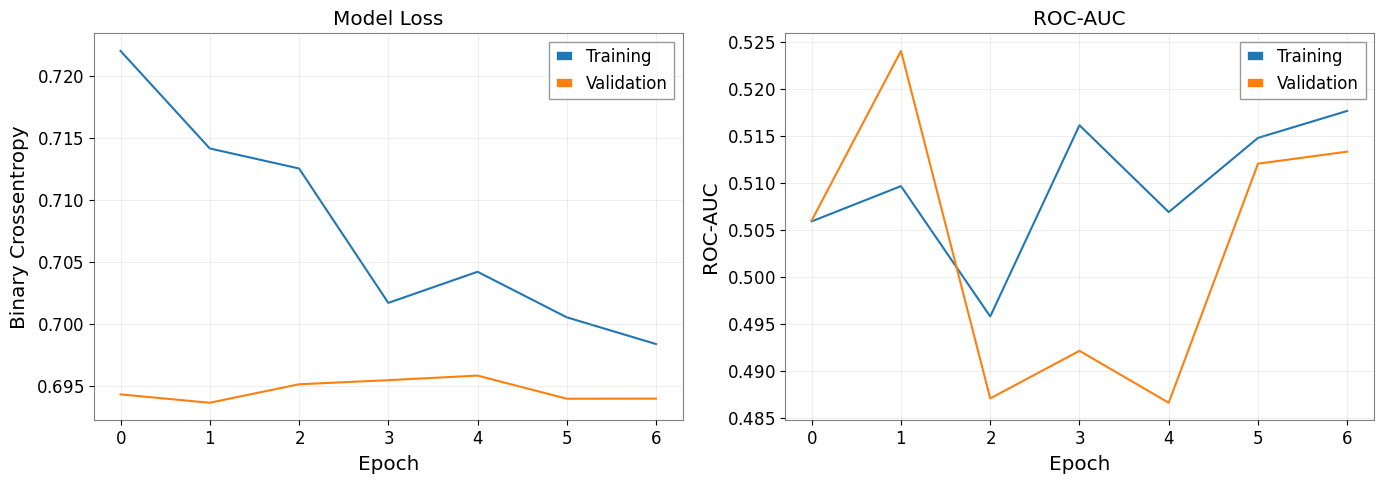

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Loss
axes[0].plot(
    history.history["loss"],
    label="Training"
)

axes[0].plot(
    history.history["val_loss"],
    label="Validation"
)

axes[0].set_title("Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ROC-AUC
axes[1].plot(
    history.history["roc_auc"],
    label="Training"
)

axes[1].plot(
    history.history["val_roc_auc"],
    label="Validation"
)

axes[1].set_title("ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluate the trained detector

38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step
ROC-AUC: 0.51897

Classification report:
              precision    recall  f1-score   support

  Background       0.50      0.76      0.60       300
      Signal       0.50      0.24      0.32       300

    accuracy                           0.50       600
   macro avg       0.50      0.50      0.46       600
weighted avg       0.50      0.50      0.46       600


Confusion matrix:
[[229  71]
 [229  71]]


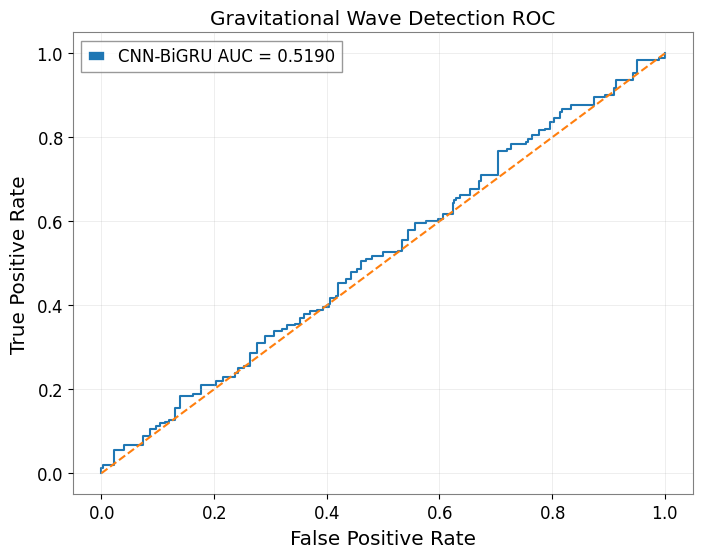

In [ ]:
y_probability = model.predict(
    X_val,
    batch_size=16
).ravel()

y_prediction = (
    y_probability >= 0.5
).astype(int)

auc = roc_auc_score(
    y_val,
    y_probability
)

fpr, tpr, thresholds = roc_curve(
    y_val,
    y_probability
)

print("ROC-AUC:", round(auc, 5))

print("\nClassification report:")

print(
    classification_report(
        y_val,
        y_prediction,
        target_names=[
            "Background",
            "Signal"
        ]
    )
)

print("\nConfusion matrix:")

print(
    confusion_matrix(
        y_val,
        y_prediction
    )
)

# Plotting ROC
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN-BiGRU AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Gravitational Wave Detection ROC")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
model.save(
    ML_DIR / "GW150914_CNN_BiGRU.keras"
)

with open(
    ML_DIR / "training_history.json",
    "w"
) as f:

    json.dump(
        history.history,
        f,
        indent=4
    )

results = {
    "architecture": "Physics-Informed CNN-BiGRU",
    "sampling_frequency": TARGET_FS,
    "window_seconds": WINDOW_SECONDS,
    "detectors": ["H1", "L1"],
    "training_samples": int(len(X_train)),
    "validation_samples": int(len(X_val)),
    "template_filters": int(template_kernels.shape[-1]),
    "roc_auc": float(auc)
}

with open(
    ML_DIR / "experiment_results.json",
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

print("Experiment saved successfully.")

Experiment saved successfully.


In [ ]:
RNG = np.random.default_rng(42)

INJECTION_SECONDS = 4
INJECTION_SAMPLES = TRAIN_FS * INJECTION_SECONDS

WAVEFORMS_FOR_INJECTION = {}

for mass_pair, waveform in WAVEFORM_BANK.items():

    hp = np.asarray(
        waveform["plus"],
        dtype=np.float64
    )

    hc = np.asarray(
        waveform["cross"],
        dtype=np.float64
    )

    hp = hp[-INJECTION_SAMPLES:]
    hc = hc[-INJECTION_SAMPLES:]

    WAVEFORMS_FOR_INJECTION[mass_pair] = {
        "plus": hp,
        "cross": hc
    }

print("Injection templates:", len(WAVEFORMS_FOR_INJECTION))

print(
    "Template duration:",
    INJECTION_SECONDS,
    "seconds"
)

Injection templates: 8
Template duration: 4 seconds


In [ ]:
def create_example_v2(window_indices, inject=False):

    idx = RNG.choice(window_indices)

    raw_noise = BACKGROUND_WINDOWS[idx]

    interval_name = WINDOW_GROUPS[idx]

    # Whiten actual detector noise
    noise = preprocess_pair(
        raw_noise,
        interval_name
    )

    noise_std = np.std(
        noise,
        axis=0,
        keepdims=True
    )

    noise_std = np.maximum(
        noise_std,
        1e-12
    )

    noise = noise / noise_std

    if not inject:

        return noise.astype(np.float32), 0

    # Selecting binary parameters
    mass_pairs = list(
        WAVEFORMS_FOR_INJECTION.keys()
    )

    mass_pair = mass_pairs[
        RNG.integers(len(mass_pairs))
    ]

    waveform = WAVEFORMS_FOR_INJECTION[
        mass_pair
    ]

    hp = waveform["plus"].copy()
    hc = waveform["cross"].copy()

    # Random polarization
    phase = RNG.uniform(
        0,
        2 * np.pi
    )

    h1_signal = (
        hp * np.cos(phase)
        - hc * np.sin(phase)
    )

    l1_signal = (
        hp * np.sin(phase)
        + hc * np.cos(phase)
    )

    # Simplified relative detector response
    l1_signal *= RNG.uniform(0.7, 1.3)

    # Random inter-detector delay
    delay = RNG.integers(
        -40,
        41
    )

    l1_signal = shift_signal(
        l1_signal,
        delay
    )

    # Random injection position
    start = RNG.integers(
        0,
        WINDOW_SAMPLES - len(hp) + 1
    )

    injection = np.zeros_like(
        raw_noise,
        dtype=np.float64
    )

    end = start + len(hp)

    injection[start:end, 0] = h1_signal
    injection[start:end, 1] = l1_signal

    # Whiten injection using same interval PSD
    injection_white = preprocess_pair(
        injection,
        interval_name
    )

    injection_white /= noise_std

    # Initial experimental network-SNR proxy
    target_snr = RNG.uniform(15, 20)

    signal_norm = np.linalg.norm(
        injection_white
    )

    if not np.isfinite(signal_norm) or signal_norm < 1e-12:

        return noise.astype(np.float32), 0

    injection_white *= (
        target_snr / signal_norm
    )

    combined = noise + injection_white

    return combined.astype(np.float32), 1

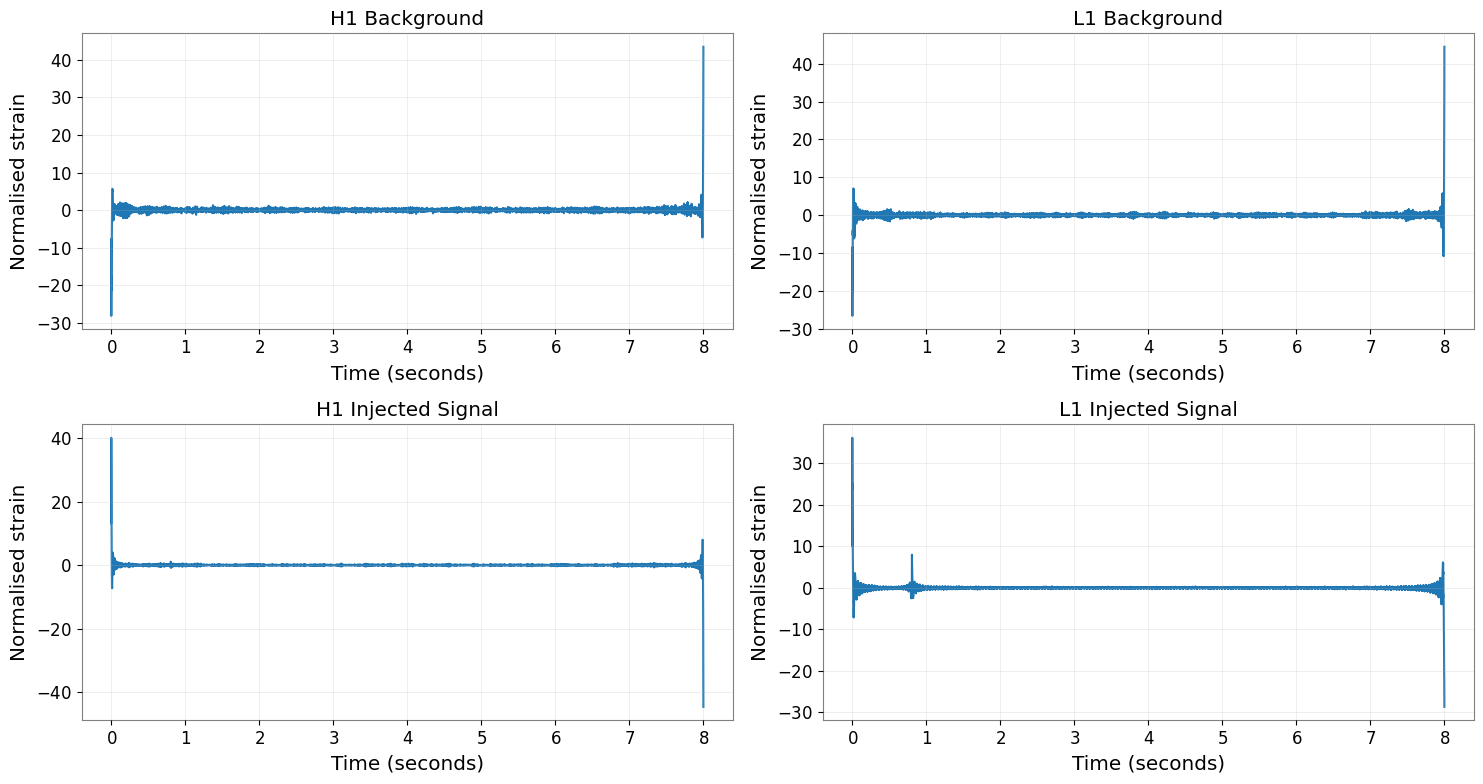

In [ ]:
sample_noise, _ = create_example_v2(
    train_indices,
    inject=False
)

sample_signal, _ = create_example_v2(
    train_indices,
    inject=True
)

time_axis = np.arange(
    8192
) / TARGET_FS

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 8)
)

axes[0, 0].plot(
    time_axis,
    sample_noise[:, 0]
)

axes[0, 0].set_title("H1 Background")

axes[0, 1].plot(
    time_axis,
    sample_noise[:, 1]
)

axes[0, 1].set_title("L1 Background")

axes[1, 0].plot(
    time_axis,
    sample_signal[:, 0]
)

axes[1, 0].set_title("H1 Injected Signal")

axes[1, 1].plot(
    time_axis,
    sample_signal[:, 1]
)

axes[1, 1].set_title("L1 Injected Signal")

for ax in axes.flat:

    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Normalised strain")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
def build_dataset_v2(number_of_samples, indices):

    X = []
    y = []

    for i in range(number_of_samples):

        inject = (i % 2 == 0)

        sample, label = create_example_v2(
            indices,
            inject=inject
        )

        X.append(sample)
        y.append(label)

        if (i + 1) % 200 == 0:

            print(
                f"Generated {i + 1}/{number_of_samples}"
            )

    return (
        np.stack(X).astype(np.float32),
        np.asarray(y, dtype=np.int32)
    )


X_train_v2, y_train_v2 = build_dataset_v2(
    4000,
    train_indices
)

X_val_v2, y_val_v2 = build_dataset_v2(
    1000,
    val_indices
)

print("Training:", X_train_v2.shape)
print("Validation:", X_val_v2.shape)

print("Training positives:", np.sum(y_train_v2 == 1))
print("Validation positives:", np.sum(y_val_v2 == 1))

Generated 200/4000
Generated 400/4000
Generated 600/4000
Generated 800/4000
Generated 1000/4000
Generated 1200/4000
Generated 1400/4000
Generated 1600/4000
Generated 1800/4000
Generated 2000/4000
Generated 2200/4000
Generated 2400/4000
Generated 2600/4000
Generated 2800/4000
Generated 3000/4000
Generated 3200/4000
Generated 3400/4000
Generated 3600/4000
Generated 3800/4000
Generated 4000/4000
Generated 200/1000
Generated 400/1000
Generated 600/1000
Generated 800/1000
Generated 1000/1000
Training: (4000, 8192, 2)
Validation: (1000, 8192, 2)
Training positives: 2000
Validation positives: 500


In [ ]:
np.savez_compressed(
    ML_DIR / "GW150914_training_v2.npz",
    X=X_train_v2,
    y=y_train_v2
)

np.savez_compressed(
    ML_DIR / "GW150914_validation_v2.npz",
    X=X_val_v2,
    y=y_val_v2
)

print("Version 2 datasets saved.")

Version 2 datasets saved.


## Establishing a conventional matched-filter baseline

# Generating a matched-filter reference waveform

In [ ]:
FS = TARGET_FS
DURATION = 8

DELTA_F = 1 / DURATION

hp, hc = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=36,
    mass2=29,
    distance=400,
    f_lower=20,
    delta_f=DELTA_F
)

print("Reference waveform generated.")
print("Frequency resolution:", DELTA_F)

Reference waveform generated.
Frequency resolution: 0.125


# Final supervised AI model

In [ ]:
ML_DIR = DATA_DIR / "ml_dataset"

train_data = np.load(
    ML_DIR / "GW150914_training_v2.npz"
)

val_data = np.load(
    ML_DIR / "GW150914_validation_v2.npz"
)

X_train_final = train_data["X"]
y_train_final = train_data["y"]

X_val_final = val_data["X"]
y_val_final = val_data["y"]

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)

print("Training class distribution:",
      np.unique(y_train_final, return_counts=True))

print("Validation class distribution:",
      np.unique(y_val_final, return_counts=True))

assert X_train_final.shape == (4000, 8192, 2)
assert X_val_final.shape == (1000, 8192, 2)

assert np.isfinite(X_train_final).all()
assert np.isfinite(X_val_final).all()

assert set(np.unique(y_train_final)) == {0, 1}
assert set(np.unique(y_val_final)) == {0, 1}

print("Final dataset validation passed.")

Training: (4000, 8192, 2)
Validation: (1000, 8192, 2)
Training class distribution: (array([0, 1], dtype=int32), array([2000, 2000]))
Validation class distribution: (array([0, 1], dtype=int32), array([500, 500]))
Final dataset validation passed.


In [ ]:
tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(42)

INPUT_SHAPE = (8192, 2)

inputs = layers.Input(
    shape=INPUT_SHAPE,
    name="H1_L1_input"
)

# Physics-informed template convolution
template_layer = layers.Conv1D(
    filters=template_kernels.shape[-1],
    kernel_size=KERNEL_SIZE,
    strides=8,
    padding="same",
    activation="relu",
    use_bias=False,
    trainable=True,
    name="physics_informed_templates"
)

x = template_layer(inputs)

template_layer.set_weights([
    template_kernels
])

# Feature extraction
x = layers.MaxPooling1D(
    pool_size=4
)(x)

x = layers.Conv1D(
    32,
    kernel_size=9,
    padding="same",
    activation="relu",
    name="feature_extractor_1"
)(x)

x = layers.BatchNormalization()(x)

x = layers.MaxPooling1D(
    pool_size=2
)(x)

x = layers.Conv1D(
    64,
    kernel_size=5,
    padding="same",
    activation="relu",
    name="feature_extractor_2"
)(x)

x = layers.Dropout(0.2)(x)

# Temporal learning
x = layers.Bidirectional(
    layers.GRU(
        32,
        return_sequences=True,
        dropout=0.15
    ),
    name="temporal_bigru"
)(x)

# Sequence aggregation
x = layers.GlobalMaxPooling1D()(x)

# Classification
x = layers.Dense(
    64,
    activation="relu"
)(x)

x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="gravitational_wave_probability"
)(x)

final_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="GW150914_Final_Physics_Informed_BiGRU"
)

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(
            name="roc_auc"
        ),
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

final_model.summary()

Model: "GW150914_Final_Physics_Informed_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ H1_L1_input (InputLayer)        │ (None, 8192, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ physics_informed_templates      │ (None, 1024, 16)       │        32,768 │
│ (Conv1D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 256, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_extractor_1 (Conv1D)    │ (None, 256, 32)        │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_extractor_2 (Conv1D)    │ (None, 128, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_bigru (Bidirectional)  │ (None, 128, 64)        │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gravitational_wave_probability  │ (None, 1)              │            65 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 70,881 (276.88 KB)

 Trainable params: 70,817 (276.63 KB)

 Non-trainable params: 64 (256.00 B)

# Verify template initialisation

In [ ]:
initialised_weights = (
    final_model
    .get_layer("physics_informed_templates")
    .get_weights()[0]
)

print("Initialised kernel shape:", initialised_weights.shape)

print(
    "Kernel weight standard deviation:",
    np.std(initialised_weights)
)

assert initialised_weights.shape == (1024, 2, 16)

assert np.isfinite(initialised_weights).all()

test_output = final_model(
    X_train_final[:2],
    training=False
)

print("Forward-pass shape:", test_output.shape)
print("Forward-pass output:", test_output.numpy())

print("Final architecture verification passed.")

Initialised kernel shape: (1024, 2, 16)
Kernel weight standard deviation: 0.022097087
Forward-pass shape: (2, 1)
Forward-pass output: [[0.5442569 ]
 [0.57332885]]
Final architecture verification passed.


In [ ]:
BEST_MODEL_PATH = (
    ML_DIR / "GW150914_FINAL_BEST.keras"
)

FINAL_MODEL_PATH = (
    ML_DIR / "GW150914_FINAL.keras"
)

callbacks_final = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_roc_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_roc_auc",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.TerminateOnNaN()
]

In [ ]:
history_final = final_model.fit(

    X_train_final,
    y_train_final,

    validation_data=(
        X_val_final,
        y_val_final
    ),

    epochs=25,

    batch_size=16,

    callbacks=callbacks_final,

    shuffle=True,

    verbose=1
)

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step - accuracy: 0.5080 - loss: 0.7106 - precision: 0.5067 - recall: 0.5121 - roc_auc: 0.5187
Epoch 1: val_roc_auc improved from None to 0.50773, saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/ml_dataset/GW150914_FINAL_BEST.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/ml_dataset/GW150914_FINAL_BEST.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 104s 396ms/step - accuracy: 0.5005 - loss: 0.7160 - precision: 0.5005 - recall: 0.5225 - roc_auc: 0.5048 - val_accuracy: 0.5050 - val_loss: 0.6936 - val_precision: 0.5026 - val_recall: 0.9800 - val_roc_auc: 0.5077 - learning_rate: 1.0000e-04
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.4998 - loss: 0.7103 - precision: 0.4990 - recall: 0.4852 - roc_auc: 0.4983
Epoch 2: val_roc_auc did not improve from 0.50773
250/250 ━━━━━━━━━━━━━━━━━━━━ 99s 397ms/step - accuracy: 0.5055 - loss: 0.7082 - precision: 0.5054 - recall: 0.5140 - roc_auc: 0.4992 - v

# Final model evaluation

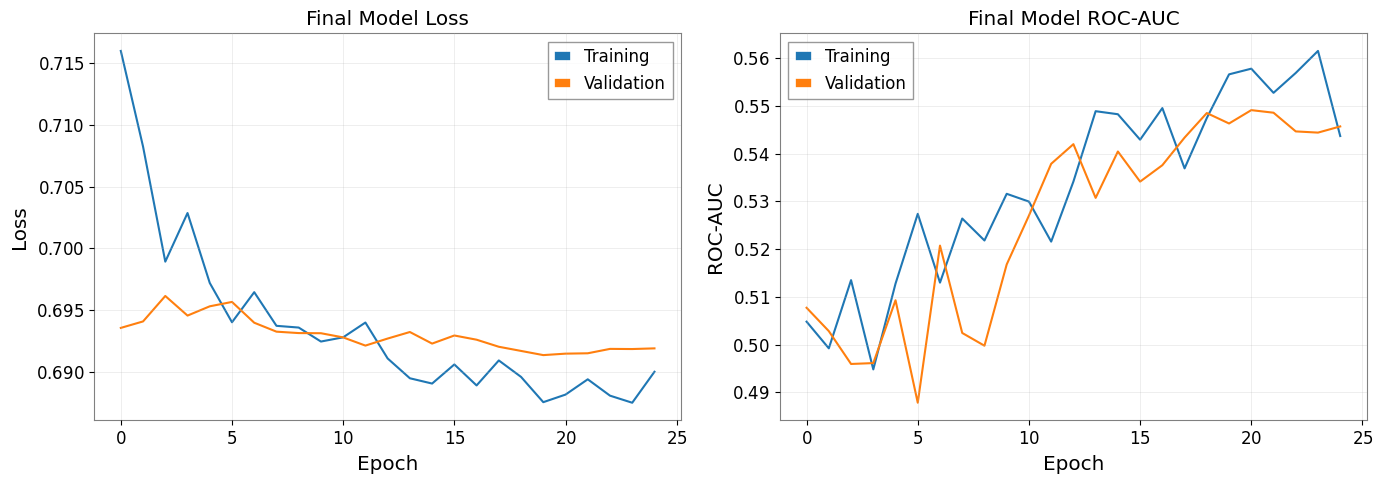

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

axes[0].plot(
    history_final.history["loss"],
    label="Training"
)

axes[0].plot(
    history_final.history["val_loss"],
    label="Validation"
)

axes[0].set_title("Final Model Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)


axes[1].plot(
    history_final.history["roc_auc"],
    label="Training"
)

axes[1].plot(
    history_final.history["val_roc_auc"],
    label="Validation"
)

axes[1].set_title("Final Model ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
y_probability_final = final_model.predict(
    X_val_final,
    batch_size=16
).ravel()

y_prediction_final = (
    y_probability_final >= 0.5
).astype(int)

final_auc = roc_auc_score(
    y_val_final,
    y_probability_final
)

final_ap = average_precision_score(
    y_val_final,
    y_probability_final
)

fpr, tpr, thresholds = roc_curve(
    y_val_final,
    y_probability_final
)

print("=" * 50)
print("FINAL GRAVITATIONAL WAVE DETECTOR")
print("=" * 50)

print("ROC-AUC:", round(final_auc, 5))
print("Average Precision:", round(final_ap, 5))

print("\nClassification Report:")

print(
    classification_report(
        y_val_final,
        y_prediction_final,
        target_names=[
            "Background",
            "Signal"
        ]
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_val_final,
        y_prediction_final
    )
)

print("\nPrevious baseline ROC-AUC:", 0.51524)

print("Final ROC-AUC:", round(final_auc, 5))

print(
    "AUC improvement:",
    round(final_auc - 0.51524, 5)
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step
FINAL GRAVITATIONAL WAVE DETECTOR
ROC-AUC: 0.55218
Average Precision: 0.5661

Classification Report:
              precision    recall  f1-score   support

  Background       0.51      0.14      0.22       500
      Signal       0.50      0.87      0.64       500

    accuracy                           0.50      1000
   macro avg       0.51      0.50      0.43      1000
weighted avg       0.51      0.50      0.43      1000

Confusion Matrix:
[[ 71 429]
 [ 67 433]]

Previous baseline ROC-AUC: 0.51524
Final ROC-AUC: 0.55218
AUC improvement: 0.03694


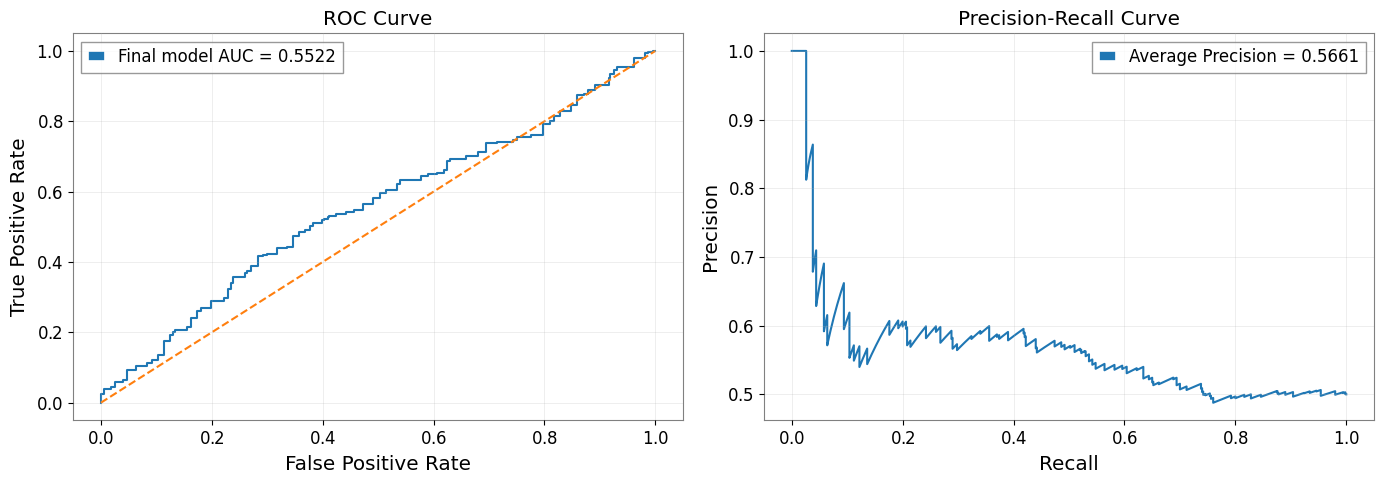

In [ ]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val_final,
    y_probability_final
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

axes[0].plot(
    fpr,
    tpr,
    label=f"Final model AUC = {final_auc:.4f}"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    "--"
)

axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)


axes[1].plot(
    recall,
    precision,
    label=f"Average Precision = {final_ap:.4f}"
)

axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
final_model.save(
    FINAL_MODEL_PATH
)

final_results = {

    "experiment": "GW150914 Final Supervised Detector",

    "architecture": "Physics-Informed CNN-BiGRU",

    "sampling_frequency": TARGET_FS,

    "window_duration": WINDOW_SECONDS,

    "detectors": ["H1", "L1"],

    "training_examples": int(len(X_train_final)),

    "validation_examples": int(len(X_val_final)),

    "template_filters": int(template_kernels.shape[-1]),

    "epochs_completed": len(
        history_final.history["loss"]
    ),

    "roc_auc": float(final_auc),

    "average_precision": float(final_ap),

    "previous_baseline_auc": 0.51524,

    "injection_method": "Simplified real-noise waveform injection",

    "snr_method": "Euclidean norm proxy, not calibrated matched-filter SNR"
}

with open(
    ML_DIR / "final_experiment_results.json",
    "w"
) as f:

    json.dump(
        final_results,
        f,
        indent=4
    )

with open(
    ML_DIR / "final_training_history.json",
    "w"
) as f:

    json.dump(
        history_final.history,
        f,
        indent=4
    )

print("Final model saved:", FINAL_MODEL_PATH)
print("Experiment metadata saved.")

Final model saved: /content/gdrive/MyDrive/NEURO_WAVE/data/ml_dataset/GW150914_FINAL.keras
Experiment metadata saved.


# Unsupervised anomaly detection

## Preparing real background data

In [ ]:
# Real background-only data
X_bg = np.asarray(WHITENED_WINDOWS, dtype=np.float32)

# Interval identity for each window
groups = np.asarray(WINDOW_GROUPS)

print("Background shape:", X_bg.shape)
print("Number of intervals:", len(np.unique(groups)))
print("Finite values:", np.isfinite(X_bg).all())

assert X_bg.ndim == 3
assert X_bg.shape[1:] == (8192, 2)
assert np.isfinite(X_bg).all()
assert len(groups) == len(X_bg)

Background shape: (480, 8192, 2)
Number of intervals: 15
Finite values: True


# Splitting by interval

In [ ]:
unique_groups = np.unique(groups)

train_groups, remaining_groups = train_test_split(
    unique_groups,
    test_size=0.40,
    random_state=42
)

cal_groups, test_groups = train_test_split(
    remaining_groups,
    test_size=0.50,
    random_state=42
)

train_idx = np.where(np.isin(groups, train_groups))[0]
cal_idx = np.where(np.isin(groups, cal_groups))[0]
test_idx = np.where(np.isin(groups, test_groups))[0]

X_train_bg = X_bg[train_idx]
X_cal_bg = X_bg[cal_idx]
X_test_bg = X_bg[test_idx]

print("Training:", X_train_bg.shape)
print("Calibration:", X_cal_bg.shape)
print("Testing:", X_test_bg.shape)

print("Train intervals:", len(train_groups))
print("Calibration intervals:", len(cal_groups))
print("Test intervals:", len(test_groups))

Training: (288, 8192, 2)
Calibration: (96, 8192, 2)
Testing: (96, 8192, 2)
Train intervals: 9
Calibration intervals: 3
Test intervals: 3


# Normalizing using training statistics


In [ ]:
channel_mean = X_train_bg.mean(axis=(0, 1), keepdims=True)
channel_std = X_train_bg.std(axis=(0, 1), keepdims=True)

channel_std = np.maximum(channel_std, 1e-8)

X_train_ae = (X_train_bg - channel_mean) / channel_std
X_cal_ae = (X_cal_bg - channel_mean) / channel_std
X_test_ae = (X_test_bg - channel_mean) / channel_std

print("Normalised training:", X_train_ae.shape)
print("Training mean:", X_train_ae.mean(axis=(0, 1)))
print("Training std:", X_train_ae.std(axis=(0, 1)))

Normalised training: (288, 8192, 2)
Training mean: [5.2103939e-09 1.7802854e-09]
Training std: [1.000264  1.0000498]


# Building the convolutional autoencoder

In [ ]:
tf.keras.backend.clear_session()

INPUT_SHAPE = (8192, 2)

inputs = layers.Input(shape=INPUT_SHAPE)

# ENCODER
x = layers.Conv1D(
    32, 7, strides=2,
    padding="same",
    activation="relu"
)(inputs)

x = layers.Conv1D(
    64, 7, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv1D(
    128, 5, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv1D(
    128, 5, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv1D(
    64, 5, strides=2,
    padding="same",
    activation="relu"
)(x)

# BOTTLENECK
latent = layers.Conv1D(
    32, 3,
    padding="same",
    activation="relu",
    name="latent_representation"
)(x)

# DECODER
x = layers.UpSampling1D(2)(latent)
x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)

x = layers.UpSampling1D(2)(x)
x = layers.Conv1D(128, 5, padding="same", activation="relu")(x)

x = layers.UpSampling1D(2)(x)
x = layers.Conv1D(128, 5, padding="same", activation="relu")(x)

x = layers.UpSampling1D(2)(x)
x = layers.Conv1D(64, 7, padding="same", activation="relu")(x)

x = layers.UpSampling1D(2)(x)

outputs = layers.Conv1D(
    2, 7,
    padding="same",
    activation="linear"
)(x)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mae"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8192, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 4096, 32)       │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2048, 64)       │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 1024, 128)      │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 512, 128)       │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 256, 64)        │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (Conv1D)  │ (None, 256, 32)        │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (None, 512, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 512, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (None, 1024, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 1024, 128)      │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_2 (UpSampling1D)  │ (None, 2048, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 2048, 128)      │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_3 (UpSampling1D)  │ (None, 4096, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 4096, 64)       │        57,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_4 (UpSampling1D)  │ (None, 8192, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 8192, 2)        │           898 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 376,962 (1.44 MB)

 Trainable params: 376,962 (1.44 MB)

 Non-trainable params: 0 (0.00 B)

# Training on background noise only

In [ ]:
ANOMALY_DIR = Path(DATA_DIR) / "anomaly_detection"
ANOMALY_DIR.mkdir(parents=True, exist_ok=True)

callbacks_ae = [
    ModelCheckpoint(
        ANOMALY_DIR / "GW150914_AUTOENCODER_BEST.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history_ae = autoencoder.fit(
    X_train_ae,
    X_train_ae,

    validation_data=(
        X_cal_ae,
        X_cal_ae
    ),

    epochs=40,
    batch_size=16,
    shuffle=True,
    callbacks=callbacks_ae,
    verbose=1
)

Epoch 1/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 0.2037
Epoch 1: val_loss improved from None to 0.20242, saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/anomaly_detection/GW150914_AUTOENCODER_BEST.keras

Epoch 1: finished saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/anomaly_detection/GW150914_AUTOENCODER_BEST.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - loss: 0.2028 - val_loss: 0.2024 - learning_rate: 1.0000e-04
Epoch 2/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 0.2010
Epoch 2: val_loss improved from 0.20242 to 0.18836, saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/anomaly_detection/GW150914_AUTOENCODER_BEST.keras

Epoch 2: finished saving model to /content/gdrive/MyDrive/NEURO_WAVE/data/anomaly_detection/GW150914_AUTOENCODER_BEST.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - loss: 0.1980 - val_loss: 0.1884 - learning_rate: 1.0000e-04
Epoch 3/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 0.1858
Epoch 3: val_loss improved from 0.18836 to 

#Plotting reconstruction learning

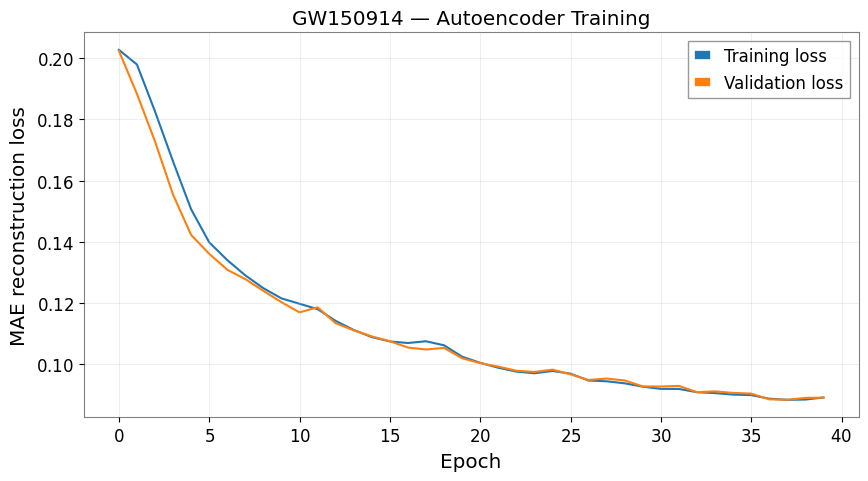

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_ae.history["loss"],
    label="Training loss"
)

plt.plot(
    history_ae.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE reconstruction loss")
plt.title("GW150914 — Autoencoder Training")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calculating anomaly scores

In [ ]:
# Reconstruct unseen background windows
cal_reconstructed = autoencoder.predict(
    X_cal_ae,
    batch_size=16,
    verbose=1
)

test_reconstructed = autoencoder.predict(
    X_test_ae,
    batch_size=16,
    verbose=1
)

# Mean absolute reconstruction error per window
cal_scores = np.mean(
    np.abs(X_cal_ae - cal_reconstructed),
    axis=(1, 2)
)

test_scores = np.mean(
    np.abs(X_test_ae - test_reconstructed),
    axis=(1, 2)
)

print("Calibration score range:",
      cal_scores.min(), cal_scores.max())

print("Test score range:",
      test_scores.min(), test_scores.max())

print("Calibration mean:", cal_scores.mean())
print("Test mean:", test_scores.mean())

6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 383ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 351ms/step
Calibration score range: 0.046973873 0.24118358
Test score range: 0.04813973 0.092328385
Calibration mean: 0.08826601
Test mean: 0.06469234


## Establishing an anomaly threshold

In [ ]:
ANOMALY_THRESHOLD = np.percentile(
    cal_scores,
    95
)

anomaly_flags = test_scores > ANOMALY_THRESHOLD

print("Anomaly threshold:", ANOMALY_THRESHOLD)

print("Test windows:", len(test_scores))

print("Flagged windows:", anomaly_flags.sum())

print(
    "Flagged percentage:",
    100 * anomaly_flags.mean()
)

Anomaly threshold: 0.17674181
Test windows: 96
Flagged windows: 0
Flagged percentage: 0.0


# Diagnosing the reconstruction scores

In [ ]:
print("X_bg shape:", X_bg.shape)
print("WINDOW_GROUPS length:", len(WINDOW_GROUPS))
print("groups length:", len(groups))

print("Calibration indices:", len(cal_idx))
print("Calibration max index:", cal_idx.max())

print("Test indices:", len(test_idx))
print("Test max index:", test_idx.max())

print("WHITENED_WINDOWS shape:", np.asarray(WHITENED_WINDOWS).shape)
print("BACKGROUND_WINDOWS shape:", np.asarray(BACKGROUND_WINDOWS).shape)
print("Original WINDOW_GROUPS length:", len(WINDOW_GROUPS))

X_bg shape: (480, 8192, 2)
WINDOW_GROUPS length: 480
groups length: 480
Calibration indices: 96
Calibration max index: 447
Test indices: 96
Test max index: 383
WHITENED_WINDOWS shape: (480, 8192, 2)
BACKGROUND_WINDOWS shape: (480, 32768, 2)
Original WINDOW_GROUPS length: 480


In [ ]:
print("========== NEURO_WAVE DATA AUDIT ==========")

print("Whitened windows:", WHITENED_WINDOWS.shape)
print("Background windows:", BACKGROUND_WINDOWS.shape)
print("Window groups:", len(WINDOW_GROUPS))

print("\nCalibration:", len(cal_idx))
print("Test:", len(test_idx))
print("Training:", len(train_idx))

print("\nSplit overlap:")
print("Train ∩ Calibration:", len(set(train_idx) & set(cal_idx)))
print("Train ∩ Test:", len(set(train_idx) & set(test_idx)))
print("Calibration ∩ Test:", len(set(cal_idx) & set(test_idx)))

print("\nIndex boundaries:")
print("Train:", min(train_idx), max(train_idx))
print("Calibration:", min(cal_idx), max(cal_idx))
print("Test:", min(test_idx), max(test_idx))

print("\nData integrity:")
print("Finite values:", np.isfinite(WHITENED_WINDOWS).all())
print("Unique groups:", len(set(WINDOW_GROUPS)))

print("\nSaved model exists:",
      os.path.exists(
          "/content/gdrive/MyDrive/NEURO_WAVE/data/anomaly_detection/GW150914_AUTOENCODER_BEST.keras"
      ))

assert len(WHITENED_WINDOWS) == len(WINDOW_GROUPS)
assert len(set(train_idx) & set(cal_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(cal_idx) & set(test_idx)) == 0

print("\nDATA AUDIT COMPLETED")


========== NEURO_WAVE DATA AUDIT ==========
Whitened windows: (480, 8192, 2)
Background windows: (480, 32768, 2)
Window groups: 480

Calibration: 96
Test: 96
Training: 288

Split overlap:
Train ∩ Calibration: 0
Train ∩ Test: 0
Calibration ∩ Test: 0

Index boundaries:
Train: 32 479
Calibration: 0 447
Test: 256 383

Data integrity:
Finite values: True
Unique groups: 15

Saved model exists: True

DATA AUDIT COMPLETED


In [ ]:
# Configuration
BASE_DIR = "/content/gdrive/MyDrive/NEURO_WAVE"

MODEL_PATH = os.path.join(
    BASE_DIR,
    "data/anomaly_detection/GW150914_AUTOENCODER_BEST.keras"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "results/final_anomaly_detection"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
THRESHOLD_PERCENTILE = 95
WINDOW_SECONDS = 8

np.random.seed(SEED)
tf.random.set_seed(SEED)

# Data validation
X = np.asarray(WHITENED_WINDOWS, dtype=np.float32)
group_ids = np.asarray(WINDOW_GROUPS)

assert X.ndim == 3
assert X.shape[1:] == (8192, 2)
assert len(X) == len(group_ids)
assert np.isfinite(X).all()

print("DATA:", X.shape)
print("UNIQUE GROUPS:", len(np.unique(group_ids)))

# Check Group Level Leakage
def group_set(indices):
    return set(group_ids[np.asarray(indices)].tolist())

train_groups = group_set(train_idx)
cal_groups = group_set(cal_idx)
test_groups = group_set(test_idx)

train_cal_overlap = train_groups & cal_groups
train_test_overlap = train_groups & test_groups
cal_test_overlap = cal_groups & test_groups

GROUP_LEAKAGE = bool(
    train_cal_overlap or
    train_test_overlap or
    cal_test_overlap
)

print("\nGROUP SPLIT AUDIT")
print("Train groups:", len(train_groups))
print("Calibration groups:", len(cal_groups))
print("Test groups:", len(test_groups))
print("Train/cal overlap:", train_cal_overlap)
print("Train/test overlap:", train_test_overlap)
print("Cal/test overlap:", cal_test_overlap)

# Load existing model

assert os.path.exists(MODEL_PATH), "Saved model not found!"

base_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("\nMODEL LOADED")
print("Input shape:", base_model.input_shape)
print("Output shape:", base_model.output_shape)

DATA: (480, 8192, 2)
UNIQUE GROUPS: 15

GROUP SPLIT AUDIT
Train groups: 9
Calibration groups: 3
Test groups: 3
Train/cal overlap: set()
Train/test overlap: set()
Cal/test overlap: set()

MODEL LOADED
Input shape: (None, 8192, 2)
Output shape: (None, 8192, 2)


In [ ]:
# REPAIR GROUP SPLITS IF NECESSARY

if GROUP_LEAKAGE:

    print("\nGROUP LEAKAGE DETECTED.")
    print("Creating independent group-based splits.")

    splitter1 = GroupShuffleSplit(
        n_splits=1,
        train_size=0.60,
        random_state=SEED
    )

    train_idx, remaining_idx = next(
        splitter1.split(X, groups=group_ids)
    )

    splitter2 = GroupShuffleSplit(
        n_splits=1,
        train_size=1/3,
        random_state=43
    )

    val_rel, remaining_rel = next(
        splitter2.split(
            X[remaining_idx],
            groups=group_ids[remaining_idx]
        )
    )

    val_idx = remaining_idx[val_rel]
    remaining_idx = remaining_idx[remaining_rel]

    splitter3 = GroupShuffleSplit(
        n_splits=1,
        train_size=0.50,
        random_state=44
    )

    cal_rel, test_rel = next(
        splitter3.split(
            X[remaining_idx],
            groups=group_ids[remaining_idx]
        )
    )

    cal_idx = remaining_idx[cal_rel]
    test_idx = remaining_idx[test_rel]

    # Starting from fresh weights, preserving the architecture.
    model = tf.keras.models.clone_model(base_model)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-4
        ),
        loss="mse"
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        )
    ]

    history = model.fit(
        X[train_idx],
        X[train_idx],
        validation_data=(
            X[val_idx],
            X[val_idx]
        ),
        epochs=40,
        batch_size=16,
        callbacks=callbacks,
        shuffle=True,
        verbose=1
    )

    model.save(MODEL_PATH)

    print("GROUP-SAFE MODEL TRAINING COMPLETED")

else:

    print("\nNo group leakage detected.")
    print("Using existing best checkpoint.")

    model = base_model

# Final group assertions
train_groups = group_set(train_idx)
cal_groups = group_set(cal_idx)
test_groups = group_set(test_idx)

assert not (train_groups & cal_groups)
assert not (train_groups & test_groups)
assert not (cal_groups & test_groups)

print("\nFINAL SPLIT")
print("Training:", len(train_idx))
print("Calibration:", len(cal_idx))
print("Testing:", len(test_idx))


No group leakage detected.
Using existing best checkpoint.

FINAL SPLIT
Training: 288
Calibration: 96
Testing: 96


In [ ]:
# Resconstruction Error Function
def reconstruction_scores(model, data):

    predictions = model.predict(
        data,
        batch_size=16,
        verbose=0
    )

    assert predictions.shape == data.shape

    errors = np.mean(
        np.square(data - predictions),
        axis=(1, 2)
    )

    channel_errors = np.mean(
        np.square(data - predictions),
        axis=1
    )

    return errors, channel_errors

# Calibration
calibration_scores, calibration_channels = (
    reconstruction_scores(
        model,
        X[cal_idx]
    )
)

ANOMALY_THRESHOLD = float(
    np.percentile(
        calibration_scores,
        THRESHOLD_PERCENTILE
    )
)

print("\nCALIBRATION")
print("Minimum:", calibration_scores.min())
print("Maximum:", calibration_scores.max())
print("Mean:", calibration_scores.mean())
print("Threshold:", ANOMALY_THRESHOLD)

# Independent Test Evaluation

test_scores, test_channels = reconstruction_scores(
    model,
    X[test_idx]
)

test_flags = (
    test_scores > ANOMALY_THRESHOLD
)

flagged_count = int(test_flags.sum())

test_count = len(test_scores)

flagged_percentage = (
    100 * flagged_count / test_count
)

print("\nTEST RESULTS")
print("Test windows:", test_count)
print("Test mean:", test_scores.mean())
print("Test maximum:", test_scores.max())
print("Threshold:", ANOMALY_THRESHOLD)
print("Flagged:", flagged_count)
print("Flagged percentage:", flagged_percentage)

# PER-CHANNEL EVALUATION

channel_names = ["Channel_0", "Channel_1"]

channel_results = {}

for i, name in enumerate(channel_names):

    channel_results[name] = {
        "calibration_mean": float(
            calibration_channels[:, i].mean()
        ),

        "test_mean": float(
            test_channels[:, i].mean()
        ),

        "test_max": float(
            test_channels[:, i].max()
        )
    }

print("\nCHANNEL RESULTS")

for name, values in channel_results.items():
    print(name, values)


CALIBRATION
Minimum: 6.8142915e+06
Maximum: 4.180329e+08
Mean: 5.0450224e+07
Threshold: 216510816.0

TEST RESULTS
Test windows: 96
Test mean: 2.3093358e+07
Test maximum: 1.0337019e+08
Threshold: 216510816.0
Flagged: 0
Flagged percentage: 0.0

CHANNEL RESULTS
Channel_0 {'calibration_mean': 23989354.0, 'test_mean': 10493744.0, 'test_max': 29188082.0}
Channel_1 {'calibration_mean': 76910928.0, 'test_mean': 35692916.0, 'test_max': 195084864.0}


In [ ]:
#CREATE FINAL RESULTS TABLE
results = pd.DataFrame({

    "original_index": test_idx,

    "background_group": group_ids[test_idx],

    "reconstruction_error": test_scores,

    "channel_0_error": test_channels[:, 0],

    "channel_1_error": test_channels[:, 1],

    "anomaly_threshold": ANOMALY_THRESHOLD,

    "anomaly_flag": test_flags.astype(int)

})

results = results.sort_values(
    "original_index"
)

results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GW150914_TEST_RESULTS.csv"
    ),
    index=False
)


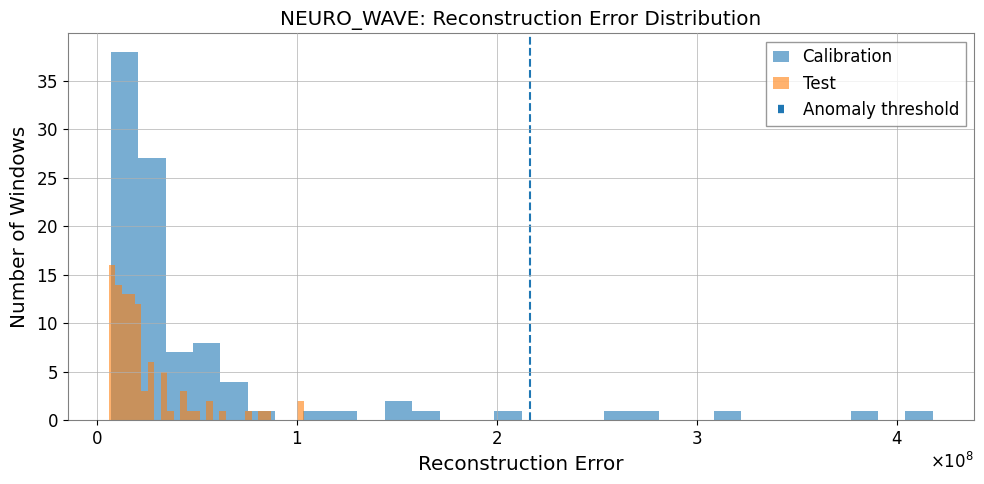

In [ ]:
#PLOT: CALIBRATION VS TEST DISTRIBUTION
plt.figure(figsize=(10, 5))

plt.hist(
    calibration_scores,
    bins=30,
    alpha=0.6,
    label="Calibration"
)

plt.hist(
    test_scores,
    bins=30,
    alpha=0.6,
    label="Test"
)

plt.axvline(
    ANOMALY_THRESHOLD,
    linestyle="--",
    label="Anomaly threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Windows")
plt.title("NEURO_WAVE: Reconstruction Error Distribution")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "01_error_distribution.png"
    ),
    dpi=200
)

plt.show()


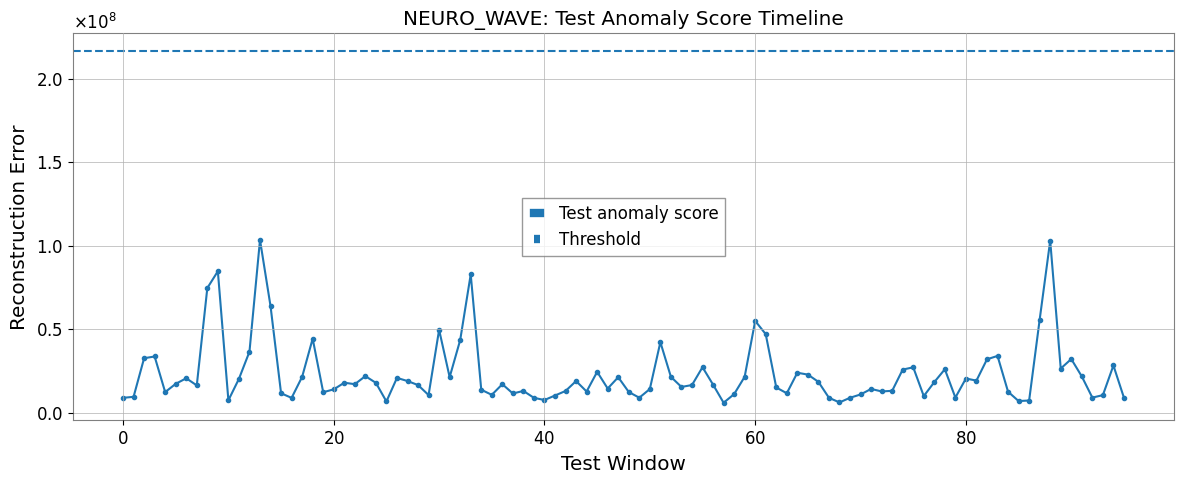

In [ ]:
#PLOT: TEST ANOMALY SCORES
plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(test_count),
    test_scores,
    marker=".",
    label="Test anomaly score"
)

plt.axhline(
    ANOMALY_THRESHOLD,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Test Window")
plt.ylabel("Reconstruction Error")
plt.title("NEURO_WAVE: Test Anomaly Score Timeline")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "02_anomaly_timeline.png"
    ),
    dpi=200
)

plt.show()


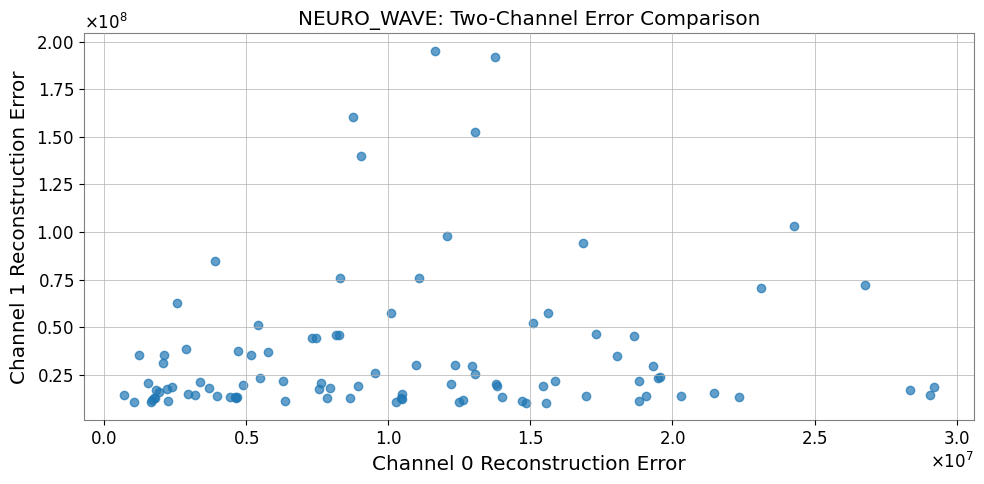

In [ ]:
#PLOT: TWO-CHANNEL COMPARISON

plt.figure(figsize=(10, 5))

plt.scatter(
    test_channels[:, 0],
    test_channels[:, 1],
    alpha=0.7
)

plt.xlabel("Channel 0 Reconstruction Error")
plt.ylabel("Channel 1 Reconstruction Error")
plt.title("NEURO_WAVE: Two-Channel Error Comparison")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "03_channel_comparison.png"
    ),
    dpi=200
)

plt.show()

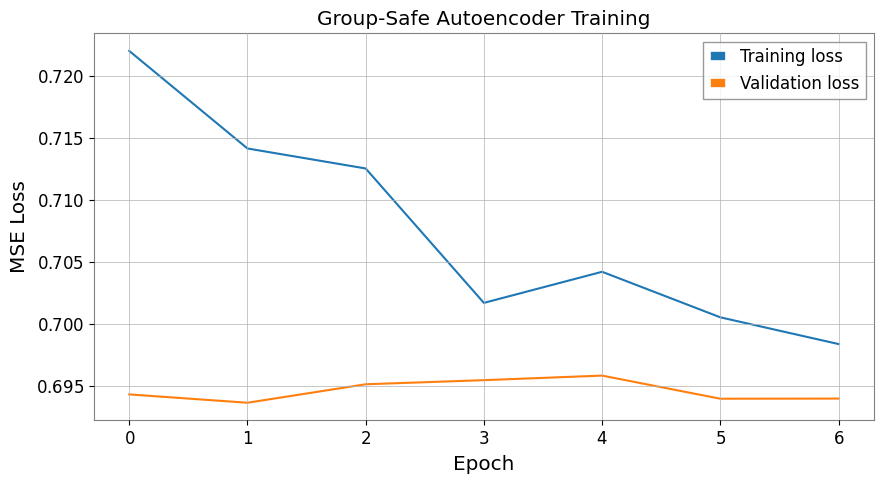

In [ ]:
if "history" in globals():

    plt.figure(figsize=(9, 5))

    plt.plot(
        history.history["loss"],
        label="Training loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title("Group-Safe Autoencoder Training")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "04_training_history.png"
        ),
        dpi=200
    )

    plt.show()


NORMALISATION RESTORED
Channel mean: [-0.05201633  0.02217931]
Channel std: [17809.123 25477.756]

Normalised shapes:
(288, 8192, 2)
(96, 8192, 2)
(96, 8192, 2)

========== CORRECTED FINAL RESULTS ==========

CALIBRATION
Minimum: 0.046973873
Maximum: 0.24118358
Mean: 0.08826601

TEST
Windows: 96
Minimum: 0.04813973
Maximum: 0.092328385
Mean: 0.06469234

DETECTION
Threshold: 0.1767418086528778
Flagged: 0
Flagged percentage: 0.0

CHANNEL 0
Calibration mean: 0.07497642
Test mean: 0.03720968
Test maximum: 0.07396215

CHANNEL 1
Calibration mean: 0.10155558
Test mean: 0.09217501
Test maximum: 0.13314244


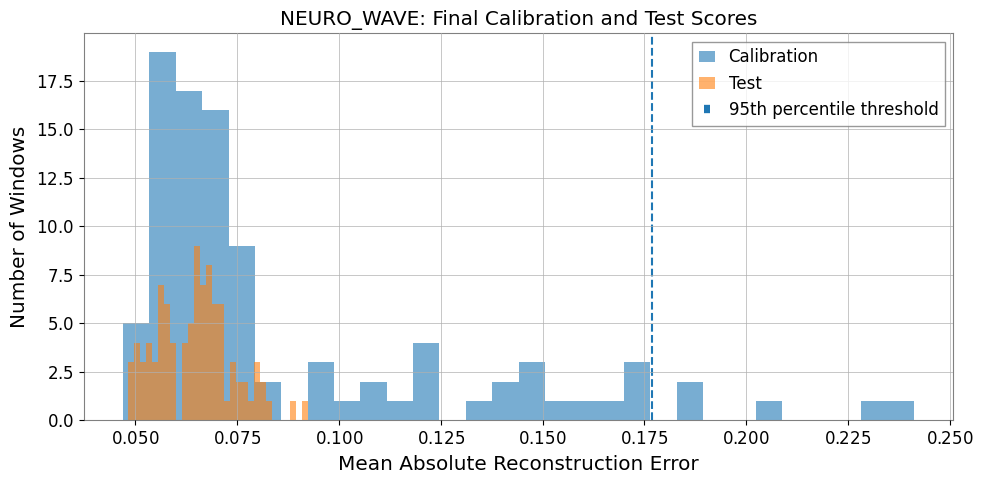

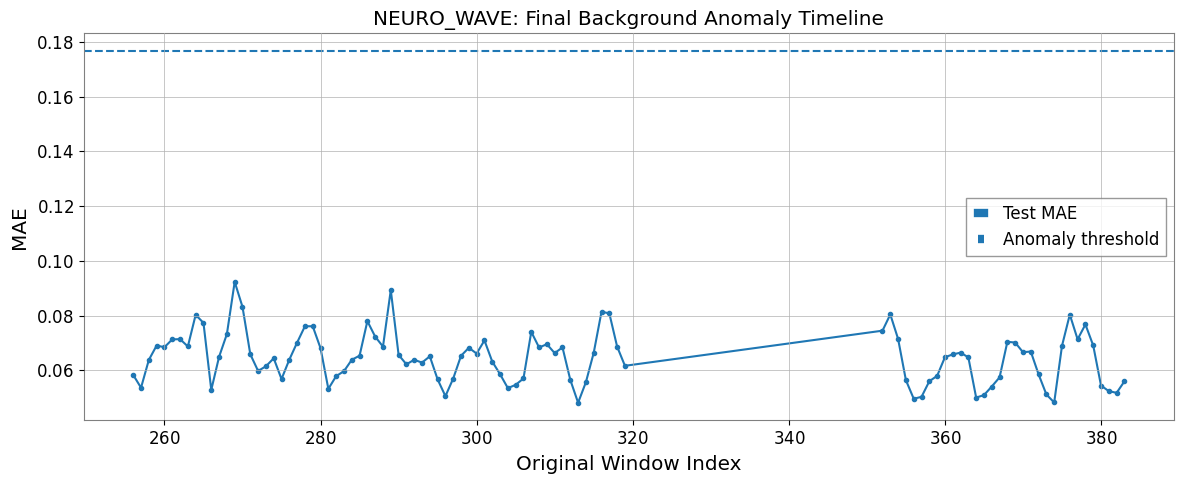

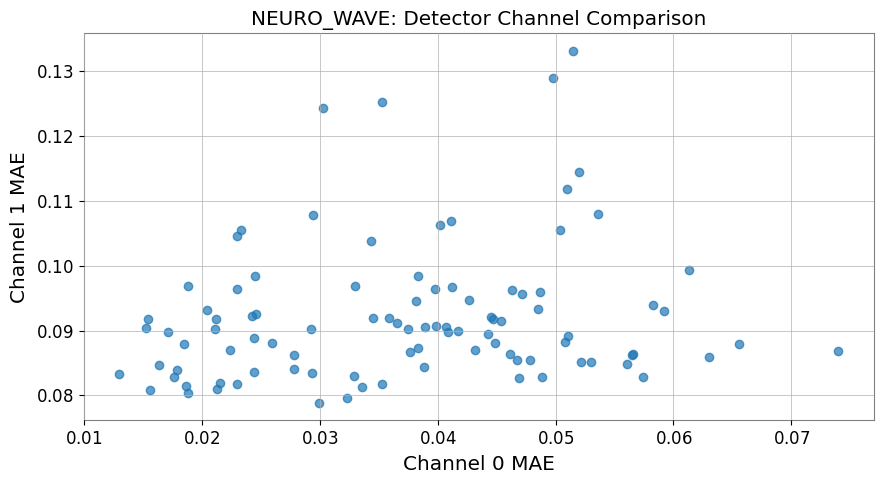


CORRECTED EVALUATION COMPLETED
Results: /content/gdrive/MyDrive/NEURO_WAVE/results/final_anomaly_detection
01_error_distribution.png
02_anomaly_timeline.png
03_channel_comparison.png
04_training_history.png
GW150914_CALIBRATION_RESULTS.csv
GW150914_NORMALISATION_PARAMETERS.npz
GW150914_TEST_RESULTS.csv
NEURO_WAVE_FINAL_SUMMARY.csv


In [ ]:
#CORRECTED FINAL AUTOENCODER EVALUATION
# Original training normalization + MAE scoring

# Og Data And Group-Safe Splits

X_bg = np.asarray(WHITENED_WINDOWS, dtype=np.float32)
group_ids = np.asarray(WINDOW_GROUPS)

assert X_bg.shape == (480, 8192, 2)

assert len(set(group_ids[train_idx]) &
           set(group_ids[cal_idx])) == 0

assert len(set(group_ids[train_idx]) &
           set(group_ids[test_idx])) == 0

assert len(set(group_ids[cal_idx]) &
           set(group_ids[test_idx])) == 0

X_train_bg = X_bg[train_idx]
X_cal_bg = X_bg[cal_idx]
X_test_bg = X_bg[test_idx]

# Restore og channel normalization

channel_mean = X_train_bg.mean(
    axis=(0, 1),
    keepdims=True
)

channel_std = X_train_bg.std(
    axis=(0, 1),
    keepdims=True
)

channel_std = np.maximum(channel_std, 1e-8)

X_train_ae = (
    X_train_bg - channel_mean
) / channel_std

X_cal_ae = (
    X_cal_bg - channel_mean
) / channel_std

X_test_ae = (
    X_test_bg - channel_mean
) / channel_std

print("NORMALISATION RESTORED")
print("Channel mean:", channel_mean.reshape(-1))
print("Channel std:", channel_std.reshape(-1))

print("\nNormalised shapes:")
print(X_train_ae.shape)
print(X_cal_ae.shape)
print(X_test_ae.shape)

MODEL_PATH = (
    "/content/gdrive/MyDrive/NEURO_WAVE/"
    "data/anomaly_detection/"
    "GW150914_AUTOENCODER_BEST.keras"
)

import tensorflow as tf

autoencoder = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)


# Og MAE Reconstruction Scoring

def calculate_mae_scores(data):

    reconstructed = autoencoder.predict(
        data,
        batch_size=16,
        verbose=0
    )

    assert reconstructed.shape == data.shape

    scores = np.mean(
        np.abs(data - reconstructed),
        axis=(1, 2)
    )

    channel_scores = np.mean(
        np.abs(data - reconstructed),
        axis=1
    )

    return scores, channel_scores

# Calibration Scores
calibration_scores, calibration_channels = (
    calculate_mae_scores(X_cal_ae)
)
# Test scores
test_scores, test_channels = (
    calculate_mae_scores(X_test_ae)
)

# Calibration threshold
THRESHOLD_PERCENTILE = 95

ANOMALY_THRESHOLD = float(
    np.percentile(
        calibration_scores,
        THRESHOLD_PERCENTILE
    )
)

test_flags = (
    test_scores > ANOMALY_THRESHOLD
)

# Final Metric
print("\n========== CORRECTED FINAL RESULTS ==========")

print("\nCALIBRATION")
print("Minimum:", calibration_scores.min())
print("Maximum:", calibration_scores.max())
print("Mean:", calibration_scores.mean())

print("\nTEST")
print("Windows:", len(test_scores))
print("Minimum:", test_scores.min())
print("Maximum:", test_scores.max())
print("Mean:", test_scores.mean())

print("\nDETECTION")
print("Threshold:", ANOMALY_THRESHOLD)
print("Flagged:", int(test_flags.sum()))
print(
    "Flagged percentage:",
    100 * test_flags.mean()
)

# Channel Evaluation

for i in range(2):

    print(f"\nCHANNEL {i}")

    print(
        "Calibration mean:",
        calibration_channels[:, i].mean()
    )

    print(
        "Test mean:",
        test_channels[:, i].mean()
    )

    print(
        "Test maximum:",
        test_channels[:, i].max()
    )

# Saving

OUTPUT_DIR = (
    "/content/gdrive/MyDrive/NEURO_WAVE/"
    "results/final_anomaly_detection"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

results = pd.DataFrame({

    "original_index": test_idx,

    "background_group": group_ids[test_idx],

    "mae_score": test_scores,

    "channel_0_mae": test_channels[:, 0],

    "channel_1_mae": test_channels[:, 1],

    "threshold": ANOMALY_THRESHOLD,

    "anomaly_flag": test_flags.astype(int)

})

results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GW150914_TEST_RESULTS.csv"
    ),
    index=False
)

# Saving calibration scores too.

pd.DataFrame({
    "calibration_index": cal_idx,
    "background_group": group_ids[cal_idx],
    "mae_score": calibration_scores
}).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "GW150914_CALIBRATION_RESULTS.csv"
    ),
    index=False
)

plt.figure(figsize=(10, 5))

plt.hist(
    calibration_scores,
    bins=30,
    alpha=0.6,
    label="Calibration"
)

plt.hist(
    test_scores,
    bins=30,
    alpha=0.6,
    label="Test"
)

plt.axvline(
    ANOMALY_THRESHOLD,
    linestyle="--",
    label="95th percentile threshold"
)

plt.xlabel("Mean Absolute Reconstruction Error")
plt.ylabel("Number of Windows")
plt.title("NEURO_WAVE: Final Calibration and Test Scores")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "01_error_distribution.png"
    ),
    dpi=200
)

plt.show()

plt.figure(figsize=(12, 5))

plt.plot(
    test_idx,
    test_scores,
    marker=".",
    label="Test MAE"
)

plt.axhline(
    ANOMALY_THRESHOLD,
    linestyle="--",
    label="Anomaly threshold"
)

plt.xlabel("Original Window Index")
plt.ylabel("MAE")
plt.title("NEURO_WAVE: Final Background Anomaly Timeline")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "02_anomaly_timeline.png"
    ),
    dpi=200
)

plt.show()

plt.figure(figsize=(9, 5))

plt.scatter(
    test_channels[:, 0],
    test_channels[:, 1],
    alpha=0.7
)

plt.xlabel("Channel 0 MAE")
plt.ylabel("Channel 1 MAE")
plt.title("NEURO_WAVE: Detector Channel Comparison")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "03_channel_comparison.png"
    ),
    dpi=200
)

plt.show()

# Save

np.savez(
    os.path.join(
        OUTPUT_DIR,
        "GW150914_NORMALISATION_PARAMETERS.npz"
    ),
    channel_mean=channel_mean,
    channel_std=channel_std
)

#FINAL SUMMARY

summary = {

    "experiment": "GW150914 Background Anomaly Detection",

    "total_windows": len(X_bg),

    "unique_groups": len(np.unique(group_ids)),

    "training_windows": len(train_idx),

    "calibration_windows": len(cal_idx),

    "test_windows": len(test_idx),

    "normalisation": "Training-only channel-wise standardisation",

    "scoring": "Mean Absolute Error",

    "threshold_percentile": THRESHOLD_PERCENTILE,

    "anomaly_threshold": ANOMALY_THRESHOLD,

    "calibration_mean_mae": float(
        calibration_scores.mean()
    ),

    "test_mean_mae": float(
        test_scores.mean()
    ),

    "test_max_mae": float(
        test_scores.max()
    ),

    "flagged_windows": int(test_flags.sum()),

    "flagged_percentage": float(
        100 * test_flags.mean()
    )

}

pd.DataFrame([summary]).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "NEURO_WAVE_FINAL_SUMMARY.csv"
    ),
    index=False
)

print("\n========================================")
print("CORRECTED EVALUATION COMPLETED")
print("========================================")
print("Results:", OUTPUT_DIR)

for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f)


In [ ]:
#FINAL INJECTION ASSET AUDIT

def inspect_array(name, value):

    arr = np.asarray(value)

    print(f"\n{name}")
    print("Shape:", arr.shape)
    print("Dtype:", arr.dtype)

    if np.issubdtype(arr.dtype, np.number):
        print("Finite:", np.isfinite(arr).all())
        print("Min:", np.nanmin(arr))
        print("Max:", np.nanmax(arr))
    else:
        print("Non-numeric metadata; finite check skipped.")
        print("Sample:", arr.flat[:3].tolist())


print("=" * 60)
print("NEURO_WAVE FINAL INJECTION AUDIT")
print("=" * 60)

# Waveform bank

for bank_name in ["WAVEFORM_BANK", "WAVEFORMS_FOR_INJECTION"]:

    bank = globals().get(bank_name)

    print(f"\n{bank_name}")

    if isinstance(bank, dict):

        print("Waveform count:", len(bank))

        for masses, polarizations in bank.items():

            print("Mass pair:", masses)

            for polarization, waveform in polarizations.items():

                inspect_array(
                    f"{polarization} waveform",
                    waveform
                )

# Background arrays

for name in [
    "BACKGROUND_WINDOWS",
    "WHITENED_WINDOWS",
    "template_kernels"
]:

    if name in globals():
        inspect_array(name, globals()[name])

# Background detector pairs

print("\nBACKGROUND_PAIRS")

for name, pair in BACKGROUND_PAIRS.items():

    inspect_array(name, pair)

    break

# PSD internal structure

print("\nPSD_DATA STRUCTURE")

for interval, psd_entry in list(PSD_DATA.items())[:2]:

    print("\nInterval:", interval)
    print("Container:", type(psd_entry).__name__)

    if isinstance(psd_entry, (list, tuple)):

        print("Length:", len(psd_entry))

        for i, element in enumerate(psd_entry):

            print("Element:", i)

            if isinstance(element, np.ndarray):
                inspect_array("PSD element", element)

            else:
                print("Type:", type(element).__name__)
                print("Value:", str(element)[:250])

# Sampling configuration

print("\nSAMPLING CONFIGURATION")

for name in [
    "TRAIN_FS",
    "TARGET_FS",
    "WINDOW_SECONDS"
]:

    if name in globals():
        print(name, "=", globals()[name])
    else:
        print(name, "= NOT FOUND")

# Normalisation

print("\nNORMALISATION")

for name in ["channel_mean", "channel_std"]:

    if name in globals():
        inspect_array(name, globals()[name])
    else:
        print(name, "NOT FOUND")

# Model

print("\nMODEL")

for name in ["autoencoder", "model"]:

    if name in globals():

        obj = globals()[name]

        if hasattr(obj, "input_shape"):
            print(name, obj.input_shape, obj.output_shape)

# Group labels

print("\nGROUP METADATA")

inspect_array("WINDOW_GROUPS", WINDOW_GROUPS)

print("\n" + "=" * 60)
print("INJECTION AUDIT FINISHED")
print("=" * 60)


NEURO_WAVE FINAL INJECTION AUDIT

WAVEFORM_BANK
Waveform count: 8
Mass pair: (20, 15)

plus waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -8.935065e-22
Max: 8.459574e-22

cross waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -8.041841e-22
Max: 8.918043e-22
Mass pair: (25, 20)

plus waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -1.1327747e-21
Max: 1.1382011e-21

cross waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -1.1637774e-21
Max: 1.0611197e-21
Mass pair: (30, 20)

plus waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -1.2601292e-21
Max: 1.1866368e-21

cross waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -1.1865396e-21
Max: 1.2339457e-21
Mass pair: (36, 29)

plus waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -1.6681694e-21
Max: 1.6295664e-21

cross waveform
Shape: (32768,)
Dtype: float32
Finite: True
Min: -1.5272169e-21
Max: 1.6689495e-21
Mass pair: (40, 30)

plus waveform
Shape: (32768,)
Dtype: float32
Fini

Fixed threshold: 0.1767418086528778
Test windows: 96
Mass configurations: 8
Prepared templates: 8
(20, 15) norm: 5.607050648338362e-25
(25, 20) norm: 6.818856123229305e-25
(30, 20) norm: 7.242521923921231e-25
(36, 29) norm: 8.9443405627668e-25
(40, 30) norm: 9.381699902119184e-25
(45, 35) norm: 1.0369238896529883e-24
(50, 40) norm: 1.1319706807795182e-24
(55, 45) norm: 1.2242491762436383e-24

Processing mass pair: (20, 15)
SNR 5: 96/96 flagged
SNR 8: 96/96 flagged
SNR 12: 96/96 flagged
SNR 16: 96/96 flagged
SNR 20: 96/96 flagged

Processing mass pair: (25, 20)
SNR 5: 96/96 flagged
SNR 8: 96/96 flagged
SNR 12: 96/96 flagged
SNR 16: 96/96 flagged
SNR 20: 96/96 flagged

Processing mass pair: (30, 20)
SNR 5: 96/96 flagged
SNR 8: 96/96 flagged
SNR 12: 96/96 flagged
SNR 16: 96/96 flagged
SNR 20: 96/96 flagged

Processing mass pair: (36, 29)
SNR 5: 96/96 flagged
SNR 8: 96/96 flagged
SNR 12: 96/96 flagged
SNR 16: 96/96 flagged
SNR 20: 96/96 flagged

Processing mass pair: (40, 30)
SNR 5: 96/96 

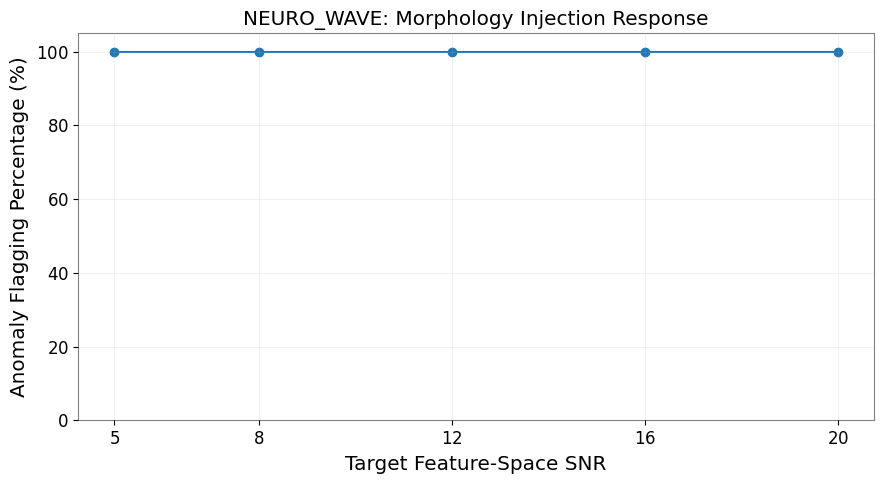

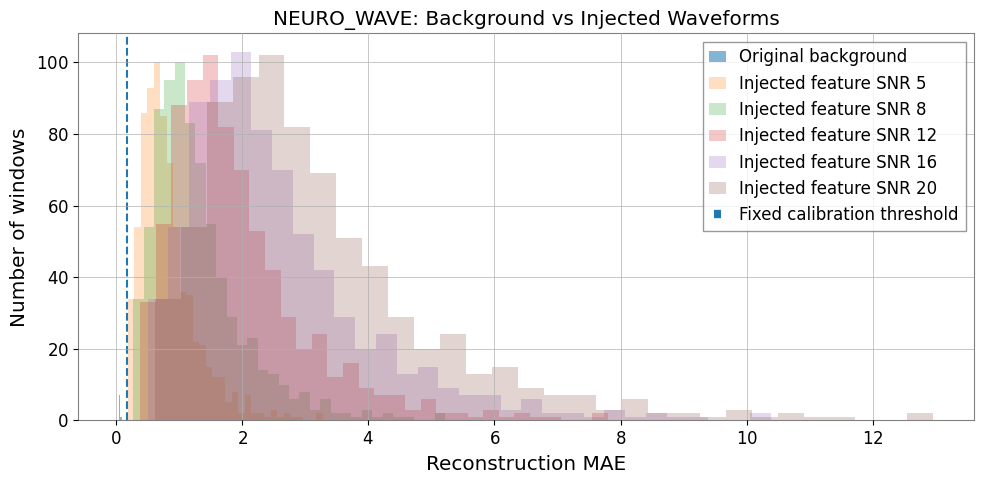

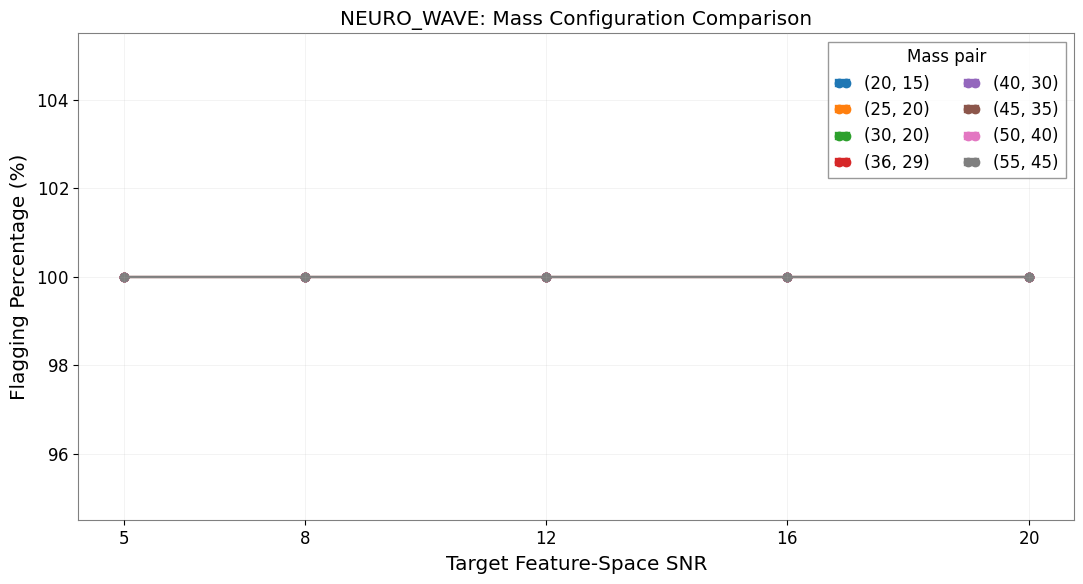


NEURO_WAVE MORPHOLOGY BENCHMARK COMPLETED
Total injection evaluations: 3840
Mass configurations: 8
Feature SNR levels: 5
Threshold: 0.1767418086528778

Saved files:
01_error_distribution.png
02_anomaly_timeline.png
03_channel_comparison.png
04_training_history.png
05_morphology_injection_response.png
06_injection_error_distributions.png
07_mass_configuration_comparison.png
GW150914_CALIBRATION_RESULTS.csv
GW150914_MORPHOLOGY_INJECTION_RESULTS.csv
GW150914_MORPHOLOGY_INJECTION_SUMMARY.csv
GW150914_NORMALISATION_PARAMETERS.npz
GW150914_TEST_RESULTS.csv
INJECTION_METHODOLOGY.txt
NEURO_WAVE_FINAL_SUMMARY.csv


In [ ]:
#FINAL GW MORPHOLOGY INJECTION BENCHMARK

# Configuration

OUT = (
    "/content/gdrive/MyDrive/NEURO_WAVE/"
    "results/final_anomaly_detection"
)

os.makedirs(OUT, exist_ok=True)

SNR_LEVELS = [5, 8, 12, 16, 20]

assert "autoencoder" in globals()
assert "WAVEFORM_BANK" in globals()
assert "test_idx" in globals()
assert "test_scores" in globals()

X = np.asarray(WHITENED_WINDOWS, dtype=np.float32)

mu = channel_mean.reshape(2)
sigma = channel_std.reshape(2)

assert np.all(sigma > 0)

# Reconstructing the original standardised test windows.
X_test = (
    X[test_idx] - mu.reshape(1, 1, 2)
) / sigma.reshape(1, 1, 2)

# Fixed threshold from independent calibration.
FIXED_THRESHOLD = float(ANOMALY_THRESHOLD)

print("Fixed threshold:", FIXED_THRESHOLD)
print("Test windows:", len(X_test))
print("Mass configurations:", len(WAVEFORM_BANK))

templates = {}

for mass_pair, polarizations in WAVEFORM_BANK.items():
    plus = np.asarray(polarizations["plus"], dtype=np.float64)
    cross = np.asarray(polarizations["cross"], dtype=np.float64)

    plus_1024 = resample_poly(plus, up=1, down=4)
    cross_1024 = resample_poly(cross, up=1, down=4)

    template = np.stack(
        [plus_1024, cross_1024],
        axis=-1
    ).astype(np.float64)

    assert template.shape == (8192, 2)
    assert np.all(np.isfinite(template))

    template_std = template / sigma.astype(np.float64).reshape(1, 2)

    template_norm = np.linalg.norm(template_std)

    assert np.isfinite(template_norm) and template_norm > 0, (
        f"Invalid template norm for {mass_pair}: {template_norm}"
    )

    templates[mass_pair] = template_std

print("Prepared templates:", len(templates))

for mass_pair, template in templates.items():
    print(mass_pair, "norm:", np.linalg.norm(template))
# Baseline Test score
baseline_scores = np.asarray(
    test_scores,
    dtype=np.float32
)

assert len(baseline_scores) == len(X_test)

# Injection experiment

records = []

for mass_pair, template in templates.items():

    print("\nProcessing mass pair:", mass_pair)

    template_norm = np.linalg.norm(template)

    assert template_norm > 0

    for target_snr in SNR_LEVELS:

        injected_batch = []

        # Setting a controlled feature-space signal-to-background
        # norm ratio for every test window.
        for background in X_test:

            background_norm = np.linalg.norm(background)

            scale = (
                target_snr *
                background_norm /
                template_norm
            )

            injected = (
                background +
                scale * template
            )

            injected_batch.append(injected)

        injected_batch = np.asarray(
            injected_batch,
            dtype=np.float32
        )

        # Evaluate in batches to limit memory usage.
        injection_scores = []

        for start in range(0, len(injected_batch), 16):

            batch = injected_batch[
                start:start + 16
            ]

            reconstruction = autoencoder.predict(
                batch,
                verbose=0
            )

            mae = np.mean(
                np.abs(batch - reconstruction),
                axis=(1, 2)
            )

            injection_scores.extend(mae.tolist())

        injection_scores = np.asarray(
            injection_scores
        )

        flags = (
            injection_scores > FIXED_THRESHOLD
        )

        # Compare each injected window with its
        # corresponding unmodified background window.
        score_increases = (
            injection_scores - baseline_scores
        )

        for i in range(len(X_test)):

            records.append({

                "mass_1": mass_pair[0],

                "mass_2": mass_pair[1],

                "target_feature_snr": target_snr,

                "original_window_index": int(
                    test_idx[i]
                ),

                "background_group": str(
                    WINDOW_GROUPS[test_idx[i]]
                ),

                "background_mae": float(
                    baseline_scores[i]
                ),

                "injected_mae": float(
                    injection_scores[i]
                ),

                "mae_increase": float(
                    score_increases[i]
                ),

                "threshold": FIXED_THRESHOLD,

                "anomaly_flag": int(flags[i])

            })

        print(
            f"SNR {target_snr}: "
            f"{flags.sum()}/{len(flags)} flagged"
        )


# Saving complete injections

injection_df = pd.DataFrame(records)

injection_path = os.path.join(
    OUT,
    "GW150914_MORPHOLOGY_INJECTION_RESULTS.csv"
)

injection_df.to_csv(
    injection_path,
    index=False
)

# Summarize recovery


summary = (
    injection_df
    .groupby("target_feature_snr")
    .agg(
        injections=("anomaly_flag", "count"),
        flagged=("anomaly_flag", "sum"),
        mean_background_mae=("background_mae", "mean"),
        mean_injected_mae=("injected_mae", "mean"),
        mean_mae_increase=("mae_increase", "mean")
    )
    .reset_index()
)

summary["flagged_percentage"] = (
    100 * summary["flagged"] /
    summary["injections"]
)

summary_path = os.path.join(
    OUT,
    "GW150914_MORPHOLOGY_INJECTION_SUMMARY.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\n========== INJECTION SUMMARY ==========")
print(summary.to_string(index=False))


# PLOT: RECOVERY VS FEATURE SNR

plt.figure(figsize=(9, 5))

plt.plot(
    summary["target_feature_snr"],
    summary["flagged_percentage"],
    marker="o"
)

plt.xlabel("Target Feature-Space SNR")
plt.ylabel("Anomaly Flagging Percentage (%)")

plt.title(
    "NEURO_WAVE: Morphology Injection Response"
)

plt.xticks(SNR_LEVELS)
plt.ylim(0, 105)
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT,
        "05_morphology_injection_response.png"
    ),
    dpi=200
)

plt.show()

# PLOT: RECONSTRUCTION ERROR DISTRIBUTIONS

plt.figure(figsize=(10, 5))

plt.hist(
    baseline_scores,
    bins=30,
    alpha=0.55,
    label="Original background"
)

for snr in SNR_LEVELS:

    subset = injection_df[
        injection_df["target_feature_snr"] == snr
    ]

    plt.hist(
        subset["injected_mae"],
        bins=30,
        alpha=0.25,
        label=f"Injected feature SNR {snr}"
    )

plt.axvline(
    FIXED_THRESHOLD,
    linestyle="--",
    label="Fixed calibration threshold"
)

plt.xlabel("Reconstruction MAE")
plt.ylabel("Number of windows")
plt.title("NEURO_WAVE: Background vs Injected Waveforms")

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT,
        "06_injection_error_distributions.png"
    ),
    dpi=200
)

plt.show()

# PLOT: MASS CONFIGURATION COMPARISON

mass_summary = (
    injection_df
    .groupby(["mass_1", "mass_2", "target_feature_snr"])
    ["anomaly_flag"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 6))

for mass_pair in templates:

    subset = mass_summary[
        (mass_summary["mass_1"] == mass_pair[0]) &
        (mass_summary["mass_2"] == mass_pair[1])
    ]

    plt.plot(
        subset["target_feature_snr"],
        subset["anomaly_flag"] * 100,
        marker="o",
        label=str(mass_pair)
    )

plt.xlabel("Target Feature-Space SNR")
plt.ylabel("Flagging Percentage (%)")
plt.title("NEURO_WAVE: Mass Configuration Comparison")

plt.xticks(SNR_LEVELS)
plt.legend(title="Mass pair", ncol=2)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT,
        "07_mass_configuration_comparison.png"
    ),
    dpi=200
)

plt.show()

methodology = """
NEURO_WAVE
GW150914 MORPHOLOGY INJECTION BENCHMARK

MODEL:
Previously trained convolutional autoencoder.
No retraining performed.

BACKGROUND:
96 independent held-out background windows.

WAVEFORMS:
Eight existing plus/cross waveform configurations.

RESAMPLING:
4096 Hz to 1024 Hz using polyphase resampling.

INJECTION:
Controlled addition in the model's standardised
feature space.

CHANNEL MAPPING:
Plus and cross polarizations are assigned to
two feature channels for a morphology benchmark.
They are NOT physical H1/L1 detector projections.

SNR:
Target feature-space norm ratio.
Not a physical gravitational-wave matched-filter SNR.

SCORING:
Mean absolute reconstruction error.

THRESHOLD:
Fixed 95th-percentile calibration threshold.
No threshold adjustment using injection outcomes.

METRICS:
Anomaly flagging fraction and reconstruction-error
change across mass configurations and feature strengths.

LIMITATIONS:
This experiment does not establish physical detector
response, astrophysical detection efficiency, H1/L1
coincidence, or real-event discovery.
"""

with open(
    os.path.join(
        OUT,
        "INJECTION_METHODOLOGY.txt"
    ),
    "w"
) as f:

    f.write(methodology)


# Final status
print("\n============================================")
print("NEURO_WAVE MORPHOLOGY BENCHMARK COMPLETED")
print("============================================")

print("Total injection evaluations:", len(injection_df))
print("Mass configurations:", len(templates))
print("Feature SNR levels:", len(SNR_LEVELS))
print("Threshold:", FIXED_THRESHOLD)

print("\nSaved files:")

for filename in sorted(os.listdir(OUT)):
    print(filename)
